In [1]:
import numpy as np
from transformers import AutoTokenizer, AutoModel
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import os
import pymanopt
from pymanopt.manifolds import Stiefel
from pymanopt.optimizers import ConjugateGradient
import autograd.numpy as anp
import kagglehub
from pathlib import Path
import json
from tqdm import tqdm

# 0. First loading of news dataset + compute embeddings

The idea is to load the dataset and compute the article embeddings once, then store them in a JSON file. Since this involves a significant amount of computation, it’s best to perform it only once.

https://www.kaggle.com/datasets/rmisra/news-category-dataset/data

> This dataset contains around 210k news headlines from 2012 to 2022 from HuffPost. This is one of the biggest news datasets and can serve as a benchmark for a variety of computational linguistic tasks. HuffPost stopped maintaining an extensive archive of news articles sometime after this dataset was first collected in 2018, so it is not possible to collect such a dataset in the present day. Due to changes in the website, there are about 200k headlines between 2012 and May 2018 and 10k headlines between May 2018 and 2022.

```
@article{misra2022news,
  title={News Category Dataset},
  author={Misra, Rishabh},
  journal={arXiv preprint arXiv:2209.11429},
  year={2022}
}
```

In [2]:
# Download latest version
path = kagglehub.dataset_download("rmisra/news-category-dataset")

print("Path to dataset files:", path)

Path to dataset files: /users/eleves-b/2023/juliette.anglade/.cache/kagglehub/datasets/rmisra/news-category-dataset/versions/3


In [3]:
# Configuration
MODEL_NAME = "answerdotai/ModernBERT-base"
OUTPUT_JSON = './data_narratives/articles_with_embeddings.json'
BATCH_SIZE = 32

def load_model():
    """Load ModernBERT model and tokenizer."""
    print("Loading ModernBERT model...")
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModel.from_pretrained(MODEL_NAME)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.eval()
    print(f"Model loaded on device: {device}")
    return tokenizer, model, device

def get_embedding(text, tokenizer, model, device):
    """Generate embedding for a single text."""
    inputs = tokenizer(text, return_tensors="pt", truncation=True,
                      max_length=512, padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputs)
        embeddings = outputs.last_hidden_state.mean(dim=1)
    return embeddings.cpu().numpy().flatten()

def compute_embeddings_from_kaggle():
    """
    Load articles from Kaggle dataset and compute embeddings.
    Saves results to JSON file.
    """
    # Load model once
    tokenizer, model, device = load_model()
    
    # Load Kaggle dataset
    fname = '.../.cache/kagglehub/datasets/rmisra/news-category-dataset/versions/3' #adapt to your path
    full_path = os.path.join(fname, 'News_Category_Dataset_v3.json')
    
    print(f"Loading dataset from: {full_path}")
    df = pd.read_json(full_path, lines=True)
    print(f"Dataset shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    
    # Create output directory
    output_dir = Path(OUTPUT_JSON).parent
    output_dir.mkdir(parents=True, exist_ok=True)
    
    # Process articles and compute embeddings
    results = []
    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Computing embeddings"):
        # Combine headline and description
        combined_text = (row.get('headline', '') or '') + ' ' + (row.get('short_description', '') or '')
        combined_text = combined_text.strip()
        
        if not combined_text:
            continue
        
        # Compute embedding
        embedding = get_embedding(combined_text, tokenizer, model, device)
        
        # Store result
        results.append({
            'idx': idx,
            'headline': row.get('headline'),
            'short_description': row.get('short_description'),
            'category': row.get('category'),
            'date': str(row.get('date')),
            'link': row.get('link'),
            'combined_text': combined_text,
            'embedding': embedding.astype(float).tolist()
        })
        
        # Save progressively every 5000 articles
        if (idx + 1) % 5000 == 0:
            print(f"Processed {idx + 1} articles, saving checkpoint...")
            with open(OUTPUT_JSON, 'w', encoding='utf-8') as f:
                json.dump(results, f, ensure_ascii=False, indent=2)
    
    # Final save
    print(f"Saving {len(results)} articles with embeddings...")
    with open(OUTPUT_JSON, 'w', encoding='utf-8') as f:
        json.dump(results, f, ensure_ascii=False, indent=2)
    
    print(f"Completed! Results saved to: {OUTPUT_JSON}")


In [4]:
""" Run only once comment the cell when done to avoid re-computation. """
#compute_embeddings_from_kaggle()

' Run only once comment the cell when done to avoid re-computation. '

# I. Data : news dataset  

Now, we assume that the dataset has been loaded and saved as explained above.

**I.1 dataset**

In [5]:
""" Loading data """
data = pd.read_json("data_narratives/resampled_articles_with_embeddings.json")

In [6]:
data.head(5)

,date,category,headline,short_description,link,embedding
0,2012-01-28,ENTERTAINMENT,'Girl With the Dragon Tattoo' India Release Ca...,"""Sony Pictures will not be releasing The Girl ...",https://www.huffingtonpost.com/entry/girl-with...,"[0.263354182243347, -0.467815995216369, 0.0798..."
1,2012-01-28,PARENTING,With Friends Like These,I didn't appreciate the freedom of introducing...,https://www.huffingtonpost.com/entry/mom-frien...,"[0.48301681876182506, -0.766911804676055, -0.4..."
2,2012-01-28,PARENTING,Confession: This Pediatrician Is a Sleep Softie,This may not be a great confession to make as ...,https://www.huffingtonpost.com/entry/co-sleepi...,"[0.529987752437591, -0.220514968037605, -0.154..."
3,2012-01-28,ENTERTAINMENT,"Sundance, Ice-T, and Shades of the American Ra...",Representation of the collective diaspora has ...,https://www.huffingtonpost.com/entry/sundance-...,"[-0.15862986445426902, -0.40649029612541204, -..."
4,2012-01-28,PARENTING,Teen Responsibility Doesn't Happen -- It's Nur...,Do you feel kids today are as responsible as k...,https://www.huffingtonpost.com/entry/teaching-...,"[0.576590120792388, -0.539305448532104, 0.1647..."


<Axes: xlabel='date'>

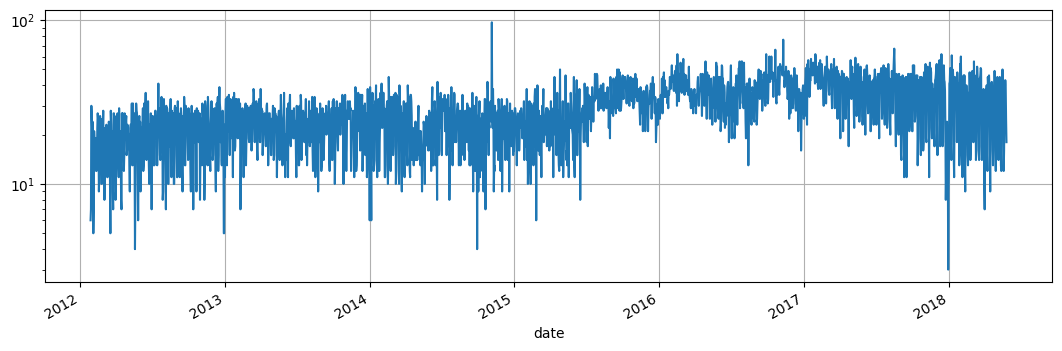

In [7]:
""" Count articles in dataset """
data.groupby('date').category.count().plot(
    figsize=(13,4), grid=True, logy=True,
)

In [8]:
data.category.value_counts()[:7]
data.groupby([data['date'].dt.year, 'category']).size()

date  category     
2012  ENTERTAINMENT      562
      PARENTING         3127
      TRAVEL            3229
2013  ENTERTAINMENT     1015
      PARENTING         4200
      TRAVEL            3384
2014  ENTERTAINMENT     2122
      PARENTING         1350
      POLITICS          3182
      TRAVEL            1861
2015  ENTERTAINMENT     3923
      POLITICS          5887
      TRAVEL             662
2016  ENTERTAINMENT     3526
      POLITICS          9990
      TRAVEL             433
2017  ENTERTAINMENT     3190
      POLITICS         10613
      TRAVEL             246
2018  ENTERTAINMENT     1720
      POLITICS          3067
      TRAVEL              72
dtype: int64

In [9]:
""" display description of dataset in a latex table """

data['year'] = data['date'].dt.year


table = data.groupby(['year', 'category']).size().unstack(fill_value=0)


latex_table = table.to_latex()

print(latex_table)

\begin{tabular}{lrrrr}
\toprule
category & ENTERTAINMENT & PARENTING & POLITICS & TRAVEL \\
year &  &  &  &  \\
\midrule
2012 & 562 & 3127 & 0 & 3229 \\
2013 & 1015 & 4200 & 0 & 3384 \\
2014 & 2122 & 1350 & 3182 & 1861 \\
2015 & 3923 & 0 & 5887 & 662 \\
2016 & 3526 & 0 & 9990 & 433 \\
2017 & 3190 & 0 & 10613 & 246 \\
2018 & 1720 & 0 & 3067 & 72 \\
\bottomrule
\end{tabular}



<Axes: xlabel='date'>

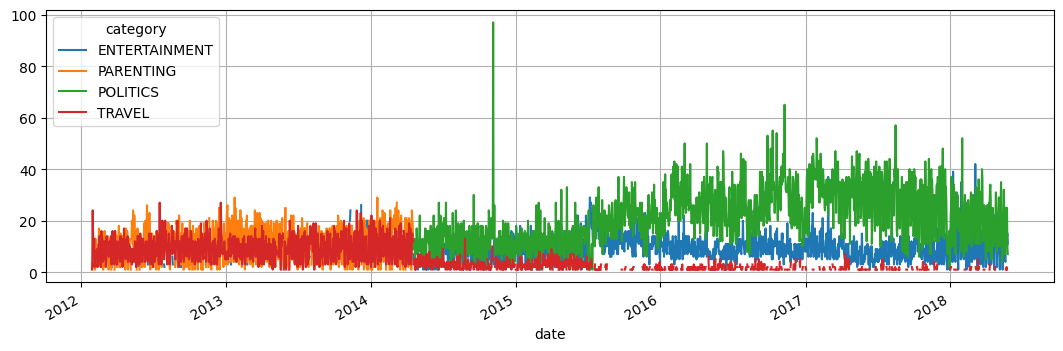

In [10]:
""" Count number of articles per category"""
daily_politics_df = data.groupby(['date', 'category']).link.count().unstack()[:'2018-06-01']
daily_politics_df.plot(
    figsize=(13,4), grid=True, logy=False,
)

In [11]:
""" load the data with embeddings """
data_with_embeddings = pd.read_json("data_narratives/resampled_articles_with_embeddings.json")
data_with_embeddings.head(5)

,date,category,headline,short_description,link,embedding
0,2012-01-28,ENTERTAINMENT,'Girl With the Dragon Tattoo' India Release Ca...,"""Sony Pictures will not be releasing The Girl ...",https://www.huffingtonpost.com/entry/girl-with...,"[0.263354182243347, -0.467815995216369, 0.0798..."
1,2012-01-28,PARENTING,With Friends Like These,I didn't appreciate the freedom of introducing...,https://www.huffingtonpost.com/entry/mom-frien...,"[0.48301681876182506, -0.766911804676055, -0.4..."
2,2012-01-28,PARENTING,Confession: This Pediatrician Is a Sleep Softie,This may not be a great confession to make as ...,https://www.huffingtonpost.com/entry/co-sleepi...,"[0.529987752437591, -0.220514968037605, -0.154..."
3,2012-01-28,ENTERTAINMENT,"Sundance, Ice-T, and Shades of the American Ra...",Representation of the collective diaspora has ...,https://www.huffingtonpost.com/entry/sundance-...,"[-0.15862986445426902, -0.40649029612541204, -..."
4,2012-01-28,PARENTING,Teen Responsibility Doesn't Happen -- It's Nur...,Do you feel kids today are as responsible as k...,https://www.huffingtonpost.com/entry/teaching-...,"[0.576590120792388, -0.539305448532104, 0.1647..."


**I.2 Resampling**

We are resampling the dataset so that, the number of articles is the same every week. We are keeping the relative proportions of all categories

In [12]:
import pandas as pd
import numpy as np

def resample_constant_weekly(df, target_per_week=None, random_state=42):
    """
    Resample a DataFrame to have a constant number of articles per week,
    while keeping the relative proportions of categories.

    Parameters
    ----------
    df : pd.DataFrame
    target_per_week : int ou None. If None: uses the median number of articles per week.
    random_state : int

    Returns
    -------
    pd.DataFrame : resampled DataFrame 
    """
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'])

    # ── 1. Create week identifier ──────────────────────────
    iso = df['date'].dt.isocalendar()
    df['year_week'] = iso['year'].astype(str) + '-W' + \
                      iso['week'].astype(str).str.zfill(2)

    # ── 2. DDetermine target number per week ───────────────────
    weekly_counts = df.groupby('year_week').size()
    if target_per_week is None:
        target_per_week = int(weekly_counts.median())

    print(f"{'Nombre cible par semaine':<35}: {target_per_week}")
    print(f"{'Nb original — min / médiane / max':<35}: "
          f"{weekly_counts.min()} / {weekly_counts.median():.0f} / {weekly_counts.max()}")

    # ── 3. Resample each week ────────────────────
    rng = np.random.RandomState(random_state)
    resampled_frames = []

    for week, week_df in df.groupby('year_week'):

        # 3a. Proportion of each category this week
        cat_counts      = week_df['category'].value_counts()
        cat_proportions = cat_counts / cat_counts.sum()

        # 3b. Proportional allocation of "target_per_week" budget 
        raw_alloc = cat_proportions * target_per_week
        alloc     = np.floor(raw_alloc).astype(int)

        # 3c. Distribute the remainder to categories with the largest fractional part
        remainder        = target_per_week - alloc.sum()
        fractional_parts = raw_alloc - alloc
        top_cats         = fractional_parts.nlargest(int(remainder)).index
        alloc[top_cats] += 1

        # 3d. Sample from each category according to the allocation
        for cat, n_sample in alloc.items():
            if n_sample == 0:
                continue
            cat_df  = week_df[week_df['category'] == cat]
            replace = n_sample > len(cat_df)         
            sampled = cat_df.sample(n=n_sample, replace=replace,
                                    random_state=rng)
            resampled_frames.append(sampled)

    # ── 4. Concatenate and clean up ───────────────────────────────
    result = pd.concat(resampled_frames, ignore_index=True)
    result.drop(columns=['year_week'], inplace=True)

    return result

In [13]:
resampled_data = resample_constant_weekly(data)
resampled_data.head(5)

Nombre cible par semaine           : 185
Nb original — min / médiane / max  : 13 / 185 / 361


,date,category,headline,short_description,link,embedding,year
0,2012-01-29,ENTERTAINMENT,World Preview Of Madonna's 'Give Me All Your L...,Fox and American Idol snagged the exclusive wo...,https://www.huffingtonpost.comhttp://insidetv....,"[0.46883603930473305, -0.654365897178649, -0.4...",2012
1,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",Bow Wow needs to hire himself a new accountant...,https://www.huffingtonpost.comhttp://www.tmz.c...,"[0.518027663230896, 0.041439708322286, -0.5698...",2012
2,2012-01-29,ENTERTAINMENT,'Terminator 3' Star Nick Stahl Arrested For No...,Nick Stahl found himself a little short on cas...,https://www.huffingtonpost.comhttp://www.tmz.c...,"[0.506560206413269, -0.08877640962600701, -0.5...",2012
3,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",Bow Wow needs to hire himself a new accountant...,https://www.huffingtonpost.comhttp://www.tmz.c...,"[0.518027663230896, 0.041439708322286, -0.5698...",2012
4,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",Bow Wow needs to hire himself a new accountant...,https://www.huffingtonpost.comhttp://www.tmz.c...,"[0.518027663230896, 0.041439708322286, -0.5698...",2012


<Axes: xlabel='date'>

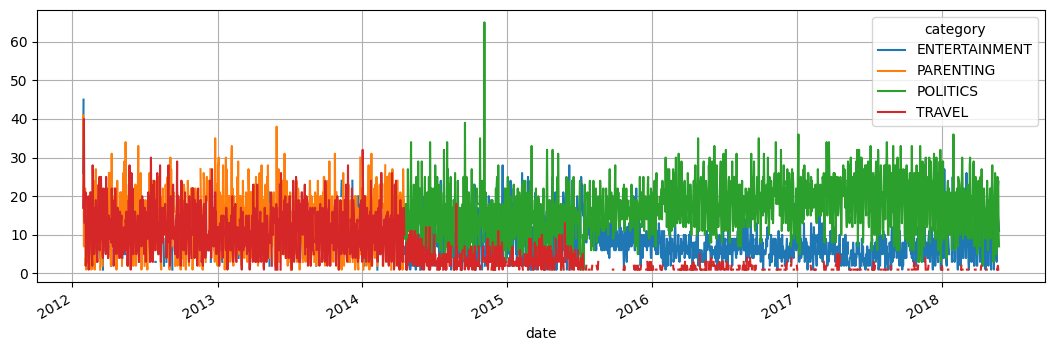

In [14]:
""" Count number of articles per category"""
daily_politics_df = resampled_data.groupby(['date', 'category']).link.count().unstack()[:'2018-06-01']
daily_politics_df.plot(
    figsize=(13,4), grid=True, logy=False,
)

<Axes: xlabel='date'>

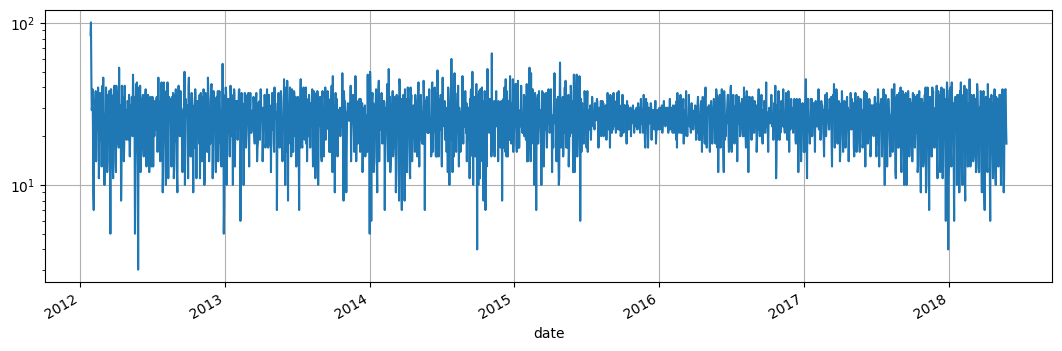

In [15]:
""" Count articles in dataset """
resampled_data.groupby('date').category.count().plot(
    figsize=(13,4), grid=True, logy=True,
)

In [16]:
resampled_data.groupby([resampled_data['date'].dt.year, 'category']).size()

date  category     
2012  ENTERTAINMENT     792
      PARENTING        4087
      TRAVEL           4221
2013  ENTERTAINMENT    1154
      PARENTING        4710
      TRAVEL           3786
2014  ENTERTAINMENT    2445
      PARENTING        1403
      POLITICS         3684
      TRAVEL           2079
2015  ENTERTAINMENT    3614
      POLITICS         5351
      TRAVEL            705
2016  ENTERTAINMENT    2478
      POLITICS         6885
      TRAVEL            311
2017  ENTERTAINMENT    2194
      POLITICS         7273
      TRAVEL            178
2018  ENTERTAINMENT    1375
      POLITICS         2450
      TRAVEL             60
dtype: int64

In [17]:
""" display description of dataset in a latex table """
resampled_data['year'] = resampled_data['date'].dt.year


table = resampled_data.groupby(['year', 'category']).size().unstack(fill_value=0)


latex_table = table.to_latex()

print(latex_table)

\begin{tabular}{lrrrr}
\toprule
category & ENTERTAINMENT & PARENTING & POLITICS & TRAVEL \\
year &  &  &  &  \\
\midrule
2012 & 792 & 4087 & 0 & 4221 \\
2013 & 1154 & 4710 & 0 & 3786 \\
2014 & 2445 & 1403 & 3684 & 2079 \\
2015 & 3614 & 0 & 5351 & 705 \\
2016 & 2478 & 0 & 6885 & 311 \\
2017 & 2194 & 0 & 7273 & 178 \\
2018 & 1375 & 0 & 2450 & 60 \\
\bottomrule
\end{tabular}



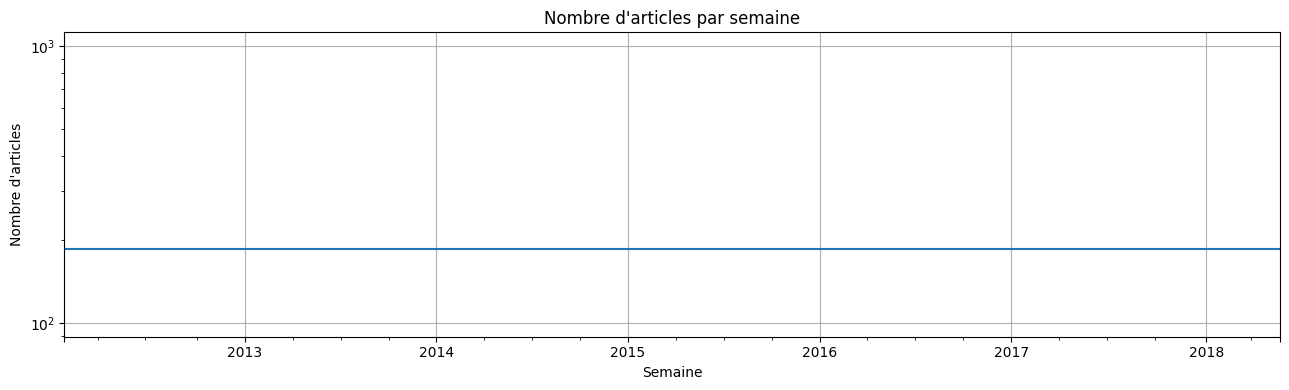

In [18]:

resampled_data['date'] = pd.to_datetime(resampled_data['date'])


resampled_data.set_index('date') \
    .resample('W')['category'] \
    .count() \
    .plot(figsize=(13, 4), grid=True, logy=True,
          title="Nombre d'articles par semaine")

plt.ylabel("Nombre d'articles")
plt.xlabel("Semaine")
plt.tight_layout()
plt.show()

## II. Narratives and orthogonalization ##


**I.1 Narratives**

We chose 3 narratives per chapter corresponding to the categories of the news in the dataset + two categories
See the conversation with chatGPT: https://chatgpt.com/share/698f503c-99d0-800d-9422-4643bc0a4340

In [19]:
narratives_by_chapter = {
    "politics": {
        "Trump_as_Disruptor_and_Institutional_Stress":
            "Donald Trump rises to and governs from power by channeling widespread distrust of political elites, media institutions, and bureaucratic authority, positioning himself as a disruptive outsider who challenges democratic norms, centralizes executive power, attacks critics, and reframes institutional resistance as partisan sabotage.",
        
        "Culture_War_and_Identity_Conflict":
            "American politics between 2012 and 2018 is structured around intensifying culture wars in which abortion, LGBTQ rights, immigration, race, religion, Confederate symbols, gun control, and voting rights become symbolic battlegrounds through which parties mobilize supporters by framing policy disagreements as existential moral conflicts.",
        
        "Welfare_State_Under_Press":
            "Debates over health care reform, Medicaid, food assistance, drug pricing, refugee policy, and regulatory protections reflect a broader struggle over the future of the American welfare state, as conservative efforts to roll back social protections clash with progressive attempts to defend or expand them in the face of economic insecurity."
    },

    "entertainment": {
        "Entertainment_as_Political_Resistance":
            "Film, television, comedy, and celebrity culture increasingly function as arenas of political contestation, where artists publicly criticize elected officials, late-night shows frame political narratives, awards ceremonies become stages for activism, and cultural production blends entertainment with explicit political messaging.",
        
        "Franchise_Nostalgia_and_Serial_Dominance":
            "The entertainment industry relies heavily on reboots, sequels, cinematic universes, and anniversary revivals, capitalizing on nostalgia and established intellectual property to secure audience loyalty in an era of streaming competition and franchise-driven box office economics.",
        
        "Celebrity_Image_Management_in_the_Social_Media_Age":
            "Celebrities navigate a hyper-visible media ecosystem in which personal relationships, identity declarations, scandals, and social media controversies become central to their public personas, requiring constant image management amid shifting norms around gender, race, and accountability."
    },

    "parenting": {
        "The_Overwhelmed_Modern_Parent":
            "Parenthood in the 2012–2018 period is portrayed as emotionally intense and structurally unsupported, with working parents—especially mothers—struggling to balance careers, childcare costs, sleep deprivation, and social expectations while navigating guilt, burnout, and economic pressure.",
        
        "Intensive_and_Expert_Guided_Parenting":
            "Raising children becomes an increasingly expert-driven project in which parents rely on scientific studies, psychological advice, educational technologies, and developmental optimization strategies to manage screen time, stress, discipline, mental health, and academic performance.",
        
        "Raising_Children_in_a_Politicized_Society":
            "Parents confront a social environment shaped by political polarization, gun violence debates, racial tensions, immigration fears, and changing gender norms, prompting concerns about children’s safety, values formation, civic identity, and exposure to divisive public discourse."
    },

    "travel": {
        "Experiential_and_Transformational_Travel":
            "Travel is framed as a path to self-discovery and cultural immersion, encouraging encounters with remote landscapes, wildlife, historic sites, and local communities as a way to cultivate authenticity, global awareness, and personal growth in an interconnected world.",
        
        "Travel_Optimization_and_Consumer_Strategy":
            "Modern travel is treated as a strategic consumer activity, with emphasis on cheapest destinations, loyalty programs, airline hacks, peak-season timing, gadget recommendations, hotel rankings, and efficiency tips that promise to maximize value, comfort, and status.",
        
        "Aesthetic_and_Instagrammable_Destinations":
            "Destinations are increasingly valued for their visual spectacle and shareability, as pink beaches, dramatic glaciers, themed hotels, architectural landmarks, and unusual experiences become curated backdrops for digital photography and social media performance."
    }
}

**II.2 Orthogonalization**

Our goal is to find a representative $V_i$ of each normalized narrative's embedding $N_i$. We are adding the mean of (N_i)_i as a last "narrative". Thus, we solve the following optimization under constraints problem: 

$$ \text{argmax}_{(V_1, ..., V_n)} \text{min}_{i} N_i^TV_i$$
$$s.t, ||V_i|| \le 1, N_i^TV_i \ge 0, V_i^TV_j = 0$$

In [20]:
def gram_schmidt(N_matrix):
    """Orthogonalization - Gram-Schmidt."""
    n, dim = N_matrix.shape
    V = np.zeros_like(N_matrix, dtype=float)

    for i in range(n):
        v = N_matrix[i].copy().astype(float)
        for j in range(i):
            v -= np.dot(v, V[j]) * V[j]
        norm = np.linalg.norm(v)
        V[i] = v / norm if norm > 1e-10 else v

    return V

In [21]:
def stiefel_optimize(N_matrix, softmin_temp=0.05, max_iter=300):
    """
    Optimization on Stiefel manifold.
    Maximizes min_i <N_i, V_i> avec V @ V.T = I.
    """
    n, dim = N_matrix.shape

    # Stiefel manifold
    manifold = Stiefel(dim, n)

    @pymanopt.function.autograd(manifold)
    def cost(V):
        Vt = V.T
        projections = anp.sum(N_matrix * Vt, axis=1)
        softmin = -softmin_temp * anp.log(anp.sum(anp.exp(-projections / softmin_temp)))
        return -softmin

    problem = pymanopt.Problem(manifold, cost)
    optimizer = ConjugateGradient(verbosity=1, max_iterations=max_iter)

    # Initialization with Gram-Schmidt
    V_init = gram_schmidt(N_matrix).T
    result = optimizer.run(problem, initial_point=V_init)

    return result.point.T, result

# III. Compute the narratives and orthogonal representatives 

The narratives need to be normalized before the orthogonalization, bacause we are optimizing on the dot product thus, if the norm of one $N_i$ is arbitrarly bigger than the others, this is inducing a bias. We don't want such a bias because after, we will work with cosine similarities. 

However, to compute the residuals, we need to keep the narratives without normalization. We denote the non-normalized narratives by $N_i^*$. Thus, the $R_i = N_i^* - V_i$

In [22]:
""" To compute embeddings with ModernBERT """

def load_model(model_name="answerdotai/ModernBERT-base"):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)
    model.eval()
    return tokenizer, model

def get_embedding(text, tokenizer, model, device):
    """
    Generate embedding for a given text using ModernBERT.
    Uses mean pooling of the last hidden state.
    """
    # Tokenize and prepare input
    inputs = tokenizer(text, return_tensors="pt", truncation=True,
                      max_length=512, padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Get embeddings
    with torch.no_grad():
        outputs = model(**inputs)
        # Mean pooling
        embeddings = outputs.last_hidden_state.mean(dim=1)

    return embeddings.cpu().numpy().flatten()

In [23]:
chapter_names = narratives_by_chapter.keys()

In [24]:
""" Compute narratives embeddings and solve orthogonality problem """
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained("answerdotai/ModernBERT-base")
model = AutoModel.from_pretrained("answerdotai/ModernBERT-base").to(device)
model.eval()

rows = []
for chapter, narratives in narratives_by_chapter.items():
    for title, text in narratives.items():
        rows.append({"chapter": chapter, "title": title, "text": text})

narrative_matrix_unorm = np.array([get_embedding(row["text"], tokenizer, model, device) for row in rows])
narrative_matrix = np.array([narrative_matrix_unorm[i] / np.linalg.norm(narrative_matrix_unorm[i]) for i in range(len(narrative_matrix_unorm))])


""" normalize each narrative"""
print(narrative_matrix.shape)

orthogonal_matrix, score = stiefel_optimize(narrative_matrix)

residuals_matrix = narrative_matrix_unorm - orthogonal_matrix
""" normalize the residuals matrix """
residuals_matrix = np.array([residuals_matrix[i] / np.linalg.norm(residuals_matrix[i]) for i in range(len(residuals_matrix))])

/users/eleves-b/2023/juliette.anglade/Desktop/Code/myenv/lib64/python3.9/site-packages/networkx/utils/backends.py:135: RuntimeWarning: networkx backend defined more than once: nx-loopback
  backends.update(_get_backends("networkx.backends"))


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The 

(12, 768)
Optimizing...
Terminated - min grad norm reached after 64 iterations, 0.11 seconds.



In [25]:
narratives = pd.DataFrame([{**rows[i], "embedding": narrative_matrix[i]} for i in range(len(rows))])
narratives_orth = pd.DataFrame([{"chapter": rows[i]["chapter"], "title": f"{rows[i]['title']}_orth", "text": rows[i]["text"], "embedding": orthogonal_matrix[i]} for i in range(len(rows))])
narratives_complementary = pd.DataFrame([{"chapter": rows[i]["chapter"], "title": f"{rows[i]['title']}_comple", "text": rows[i]["text"], "embedding": residuals_matrix[i]} for i in range(len(rows))])

narratives.to_csv("./data_narratives/narratives.csv", index=False)
narratives_orth.to_csv("./data_narratives/narratives_orth.csv", index=False)
narratives_complementary.to_csv("./data_narratives/narratives_complementary.csv", index=False)

In [26]:
narrative_names = (narratives.chapter + ':' + narratives.title).to_list()

orthogonal_names = (narratives_orth.chapter + ':' + narratives_orth.title).to_list()

residuals_names = (narratives_complementary.chapter + ':' + narratives_complementary.title).to_list()


**III.2 Visualization**

In [27]:
cosine_sim_all = cosine_similarity(np.vstack([narrative_matrix, orthogonal_matrix, residuals_matrix]))

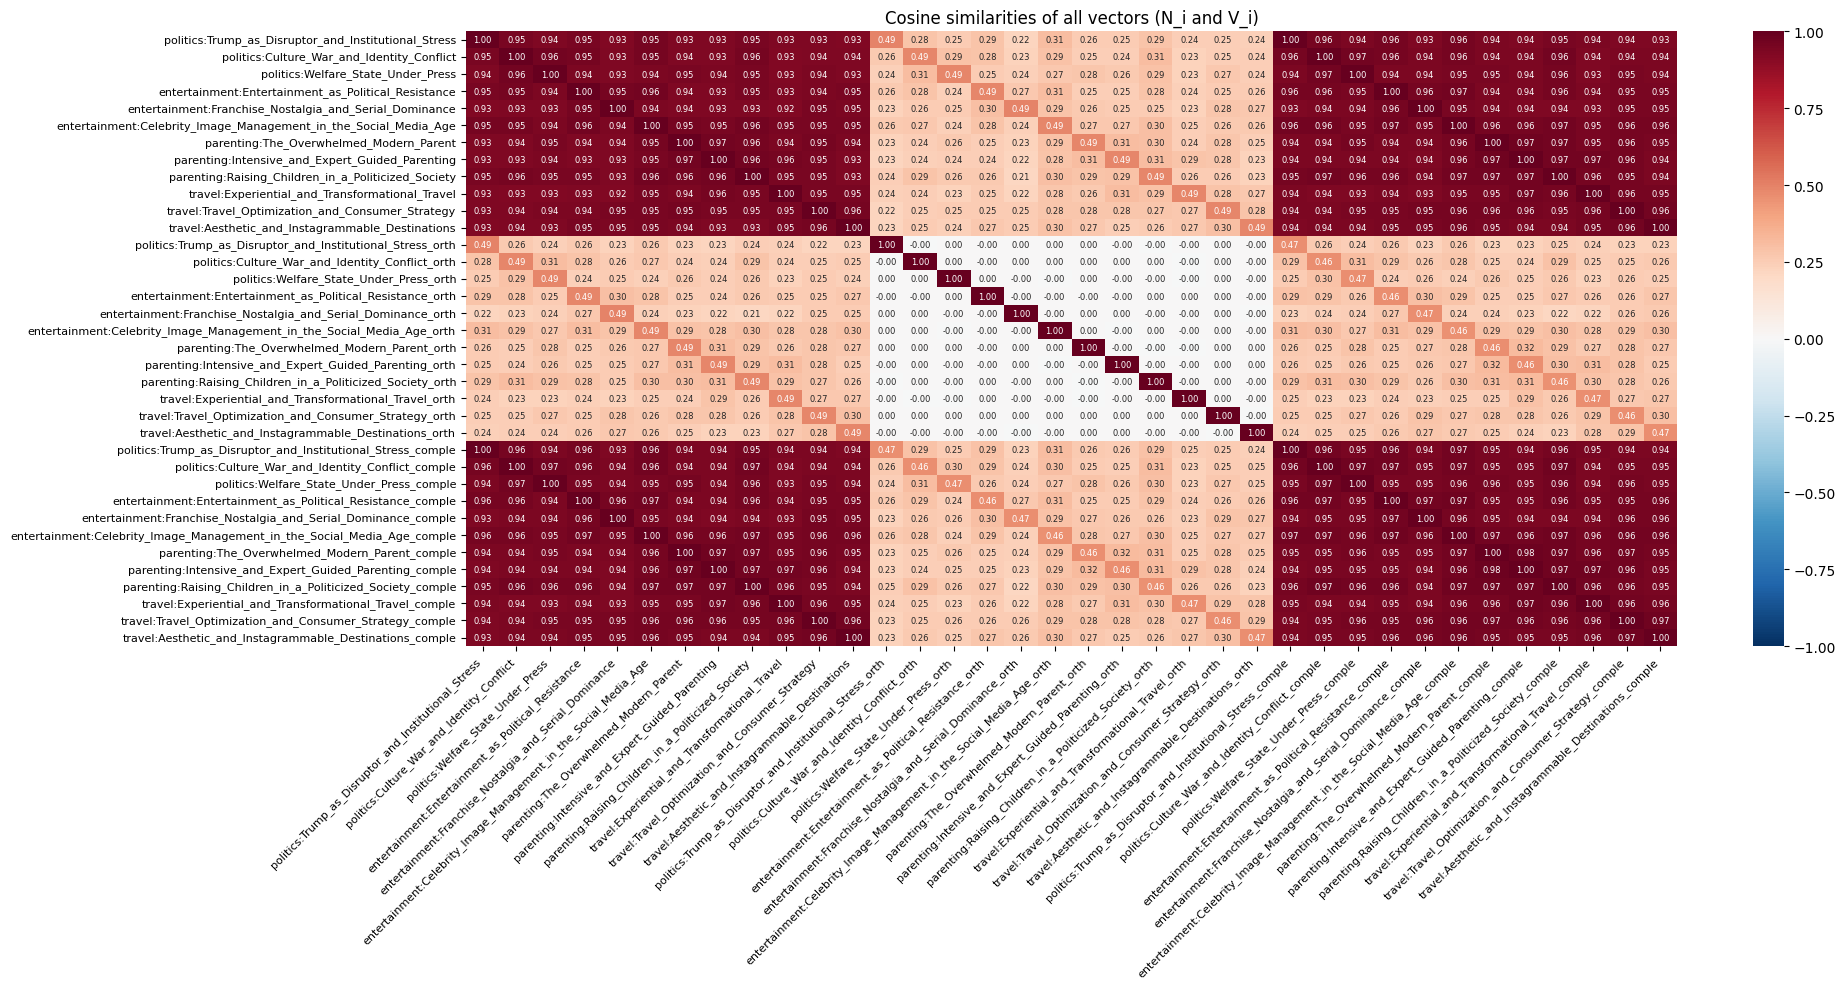

In [28]:
fig, axes = plt.subplots(1, 1, figsize=(20, 10))
# Heatmap for all vectors N_i and V_i, N_i - V_i
sns.heatmap(
    cosine_sim_all,
    xticklabels=narrative_names + orthogonal_names + residuals_names,
    yticklabels=narrative_names + orthogonal_names + residuals_names,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes.set_title('Cosine similarities of all vectors (N_i and V_i)', fontsize=12)
axes.tick_params(axis='x', rotation=45, labelsize=8)
axes.tick_params(axis='y', rotation=0, labelsize=8)
plt.setp(axes.get_xticklabels(), rotation=45, ha="right")
plt.setp(axes.get_yticklabels(), rotation=0)



plt.tight_layout()
plt.savefig('cosine_similarities_all.png', dpi=150, bbox_inches='tight')
plt.show()

**III.3 Orthogonalization adding the mean of the narratives**

Now, let's see what happens if we had the mean of the narratives, i.e : $M = \frac1n \sum_i N_i$

In [29]:
narratives_with_mean_matrix = np.vstack([narrative_matrix, narrative_matrix.mean(axis=0)])
narratives_with_mean_matrix_unorm = np.vstack([narrative_matrix_unorm, narrative_matrix_unorm.mean(axis=0)])
orthogonal_with_mean_matrix, _= stiefel_optimize(narratives_with_mean_matrix)
rediduals_with_mean_matrix = narratives_with_mean_matrix_unorm - orthogonal_with_mean_matrix

Optimizing...
Terminated - min grad norm reached after 71 iterations, 0.04 seconds.



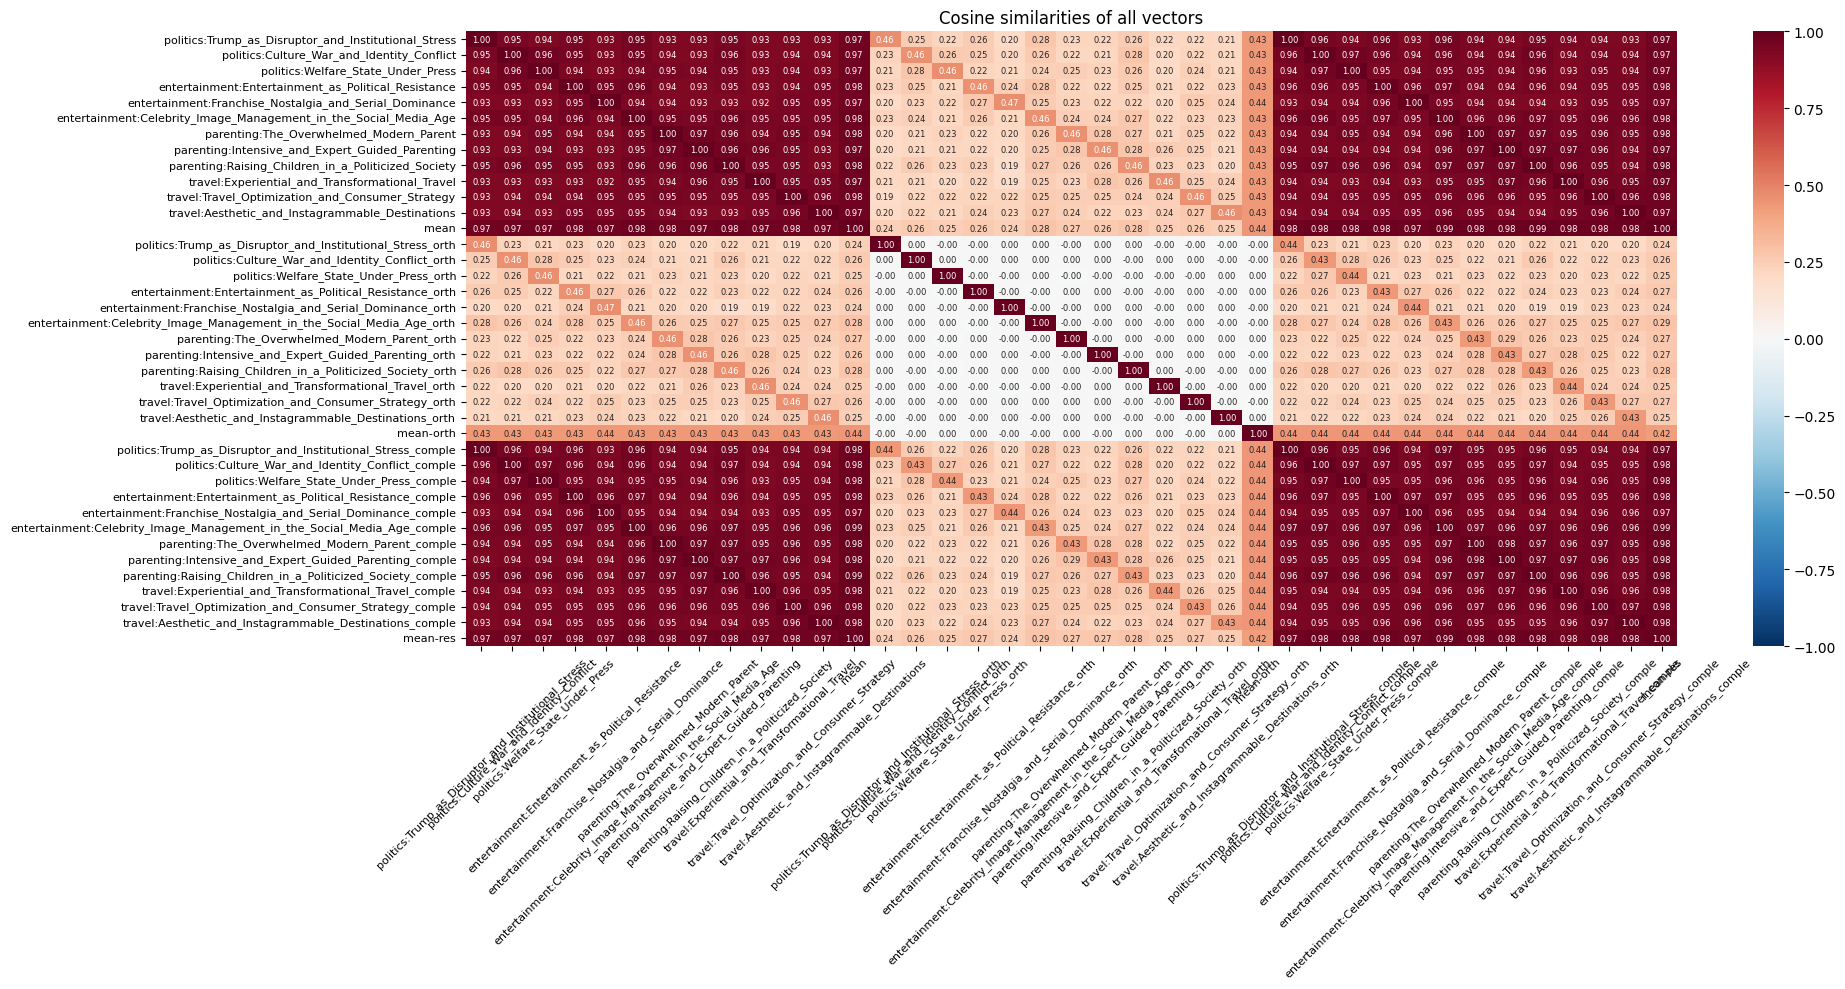

In [30]:
"""visualization"""
 
cosine_sim_all_with_mean = cosine_similarity(np.vstack([narratives_with_mean_matrix, orthogonal_with_mean_matrix, rediduals_with_mean_matrix]))

fig, axes = plt.subplots(1, 1, figsize=(20, 10))
# Heatmap for all vectors N_i and V_i, N_i - V_i
sns.heatmap(
    cosine_sim_all_with_mean,
    xticklabels=narrative_names+ ["mean"] + orthogonal_names + ["mean-orth"] + residuals_names + ["mean-res"],
    yticklabels=narrative_names + ["mean"] + orthogonal_names + ["mean-orth"] + residuals_names + ["mean-res"],
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes.set_title('Cosine similarities of all vectors', fontsize=12)
axes.tick_params(axis='x', rotation=45, labelsize=8)
axes.tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.show()

This is just an exmaple. We won't use this method.

# IV Main computations: cosine similarities with $N_i$, $V_i$, $R_i$

For this part, we are keeping the $V_i$ and $R_i$ without adding the mean in the orthogonalization process.

In [31]:
"""Create dataframe with the cosine similarity with orthogonal narratives"""
from tqdm.notebook import tqdm
from sklearn.metrics.pairwise import cosine_similarity

print("Computing cosine similarities with narratives and orthogonal narratives...")


time_series_data = []
gdir = './data_narratives'

for idx, row in tqdm(resampled_data.iterrows(), total=len(resampled_data)):
    # Get article embedding
    article_embedding = row['embedding']
    if isinstance(article_embedding, list):
        article_embedding = np.array(article_embedding)
    
    info_similarities = {
        'date': row['date'],
        'category': row['category'],
        'headline': row['headline'],
        'link': row.get('link', '')
    }
    
    # Compute cosine similarities with narratives (vectorized)
    similarities_narratives = cosine_similarity(
        article_embedding.reshape(1, -1),
        narrative_matrix
    )[0]
    
    for name, sim in zip(narrative_names, similarities_narratives):
        info_similarities[f"{name}"] = float(sim)
    
    # Compute cosine similarities with orthogonal narratives (vectorized)
    similarities_orthogonal = cosine_similarity(
        article_embedding.reshape(1, -1),
        orthogonal_matrix
    )[0]

    for name, sim in zip(orthogonal_names, similarities_orthogonal):
        info_similarities[f"{name}"] = float(sim)

    # Compute cosine similarities with residuals narratives (vectorized)
    similarities_residuals = cosine_similarity(
        article_embedding.reshape(1, -1),
        residuals_matrix
    )[0]
    
    for name, sim in zip(residuals_names, similarities_residuals):
        info_similarities[f"{name}"] = float(sim)

    time_series_data.append(info_similarities)

# Save to CSV
ts_df = pd.DataFrame(time_series_data)
filepath = os.path.join(gdir, 'narrative_exposures_with_orthogonal.csv')
os.makedirs(gdir, exist_ok=True)
ts_df.to_csv(filepath, index=False)
print(f"✓ Saved to: {filepath}")
print(f"Shape: {ts_df.shape}")
print(f"Columns: {ts_df.columns.tolist()[:10]}...")  # Show first 10 columns

Computing cosine similarities with narratives and orthogonal narratives...


  0%|          | 0/61235 [00:00<?, ?it/s]

✓ Saved to: ./data_narratives/narrative_exposures_with_orthogonal.csv
Shape: (61235, 40)
Columns: ['date', 'category', 'headline', 'link', 'politics:Trump_as_Disruptor_and_Institutional_Stress', 'politics:Culture_War_and_Identity_Conflict', 'politics:Welfare_State_Under_Press', 'entertainment:Entertainment_as_Political_Resistance', 'entertainment:Franchise_Nostalgia_and_Serial_Dominance', 'entertainment:Celebrity_Image_Management_in_the_Social_Media_Age']...


In [32]:
ts_df.head()

,date,category,headline,link,politics:Trump_as_Disruptor_and_Institutional_Stress,politics:Culture_War_and_Identity_Conflict,politics:Welfare_State_Under_Press,entertainment:Entertainment_as_Political_Resistance,entertainment:Franchise_Nostalgia_and_Serial_Dominance,entertainment:Celebrity_Image_Management_in_the_Social_Media_Age,...,politics:Welfare_State_Under_Press_comple,entertainment:Entertainment_as_Political_Resistance_comple,entertainment:Franchise_Nostalgia_and_Serial_Dominance_comple,entertainment:Celebrity_Image_Management_in_the_Social_Media_Age_comple,parenting:The_Overwhelmed_Modern_Parent_comple,parenting:Intensive_and_Expert_Guided_Parenting_comple,parenting:Raising_Children_in_a_Politicized_Society_comple,travel:Experiential_and_Transformational_Travel_comple,travel:Travel_Optimization_and_Consumer_Strategy_comple,travel:Aesthetic_and_Instagrammable_Destinations_comple
0,2012-01-29,ENTERTAINMENT,World Preview Of Madonna's 'Give Me All Your L...,https://www.huffingtonpost.comhttp://insidetv....,0.872088,0.884405,0.883082,0.884446,0.884307,0.889044,...,0.888900,0.889924,0.890113,0.894087,0.898142,0.897087,0.888884,0.889370,0.892401,0.893805
1,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",https://www.huffingtonpost.comhttp://www.tmz.c...,0.902042,0.897098,0.909336,0.888412,0.889751,0.906113,...,0.914077,0.895459,0.896638,0.910999,0.923574,0.911410,0.908064,0.899748,0.911864,0.902387
2,2012-01-29,ENTERTAINMENT,'Terminator 3' Star Nick Stahl Arrested For No...,https://www.huffingtonpost.comhttp://www.tmz.c...,0.894750,0.897866,0.899732,0.893721,0.899954,0.904945,...,0.905360,0.899992,0.905617,0.909648,0.917965,0.901946,0.898209,0.892755,0.908184,0.906215
3,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",https://www.huffingtonpost.comhttp://www.tmz.c...,0.902042,0.897098,0.909336,0.888412,0.889751,0.906113,...,0.914077,0.895459,0.896638,0.910999,0.923574,0.911410,0.908064,0.899748,0.911864,0.902387
4,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",https://www.huffingtonpost.comhttp://www.tmz.c...,0.902042,0.897098,0.909336,0.888412,0.889751,0.906113,...,0.914077,0.895459,0.896638,0.910999,0.923574,0.911410,0.908064,0.899748,0.911864,0.902387


# V Visualization

**V.1 All new, all narratives**

1) Narratives $N_i$

In [33]:
""" Prepare data for visualization """
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Extract narrative columns (those with ':' in the name)
all_cols = [col for col in ts_df.columns if ':' in col]

# Separate narratives and orthogonal narratives
narrative_cols = [col for col in all_cols if '_orth' not in col and '_comple' not in col]
orthogonal_cols = [col for col in all_cols if '_orth' in col]
residuals_cols = [col for col in all_cols if '_comple' in col]

# Get unique news categories
news_categories = sorted(ts_df['category'].unique()) 


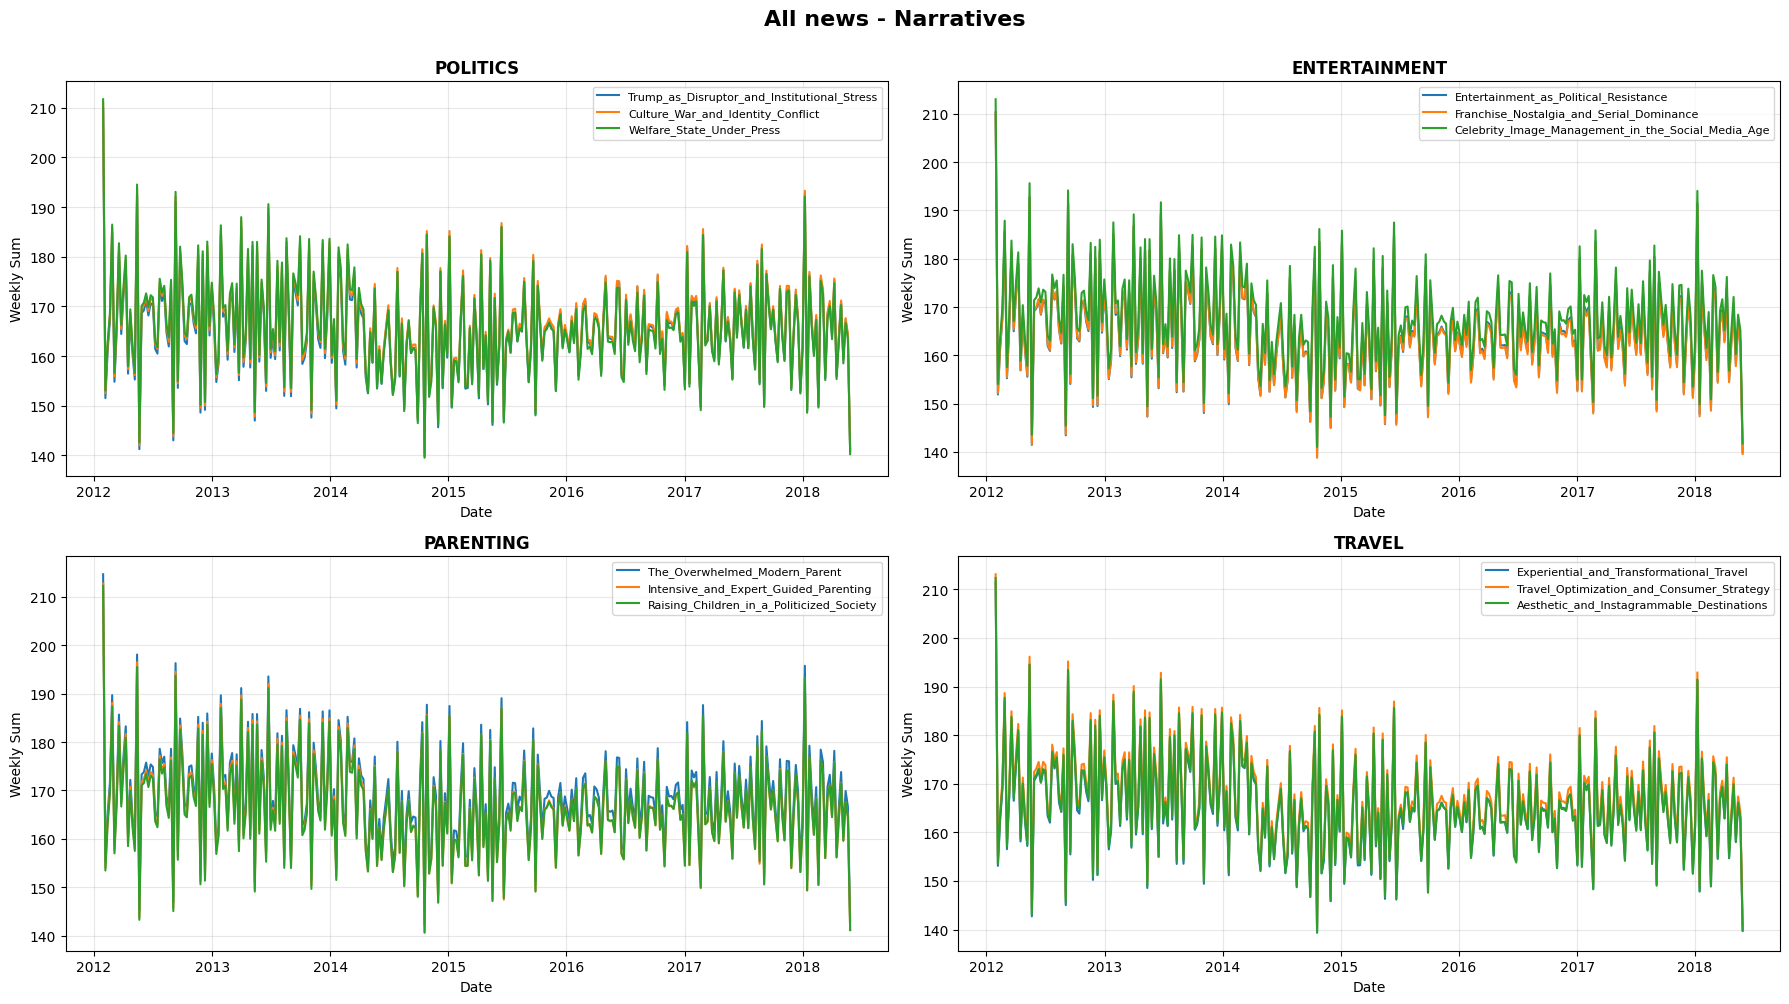

In [34]:
""" Visualization of cosine time series for pure narratives """


# Create subplots: one per chapter (6 chapters)
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()
    
for ax_idx, chapter in enumerate(chapter_names):
    chapter_narrative_cols = [col for col in narrative_cols if col.startswith(chapter + ':')]
        
    if not chapter_narrative_cols:
        axes[ax_idx].set_visible(False)
        continue
        
    for col in chapter_narrative_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Sum', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
fig.suptitle('All news - Narratives', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


2) Orthogonal representatives $V_i$

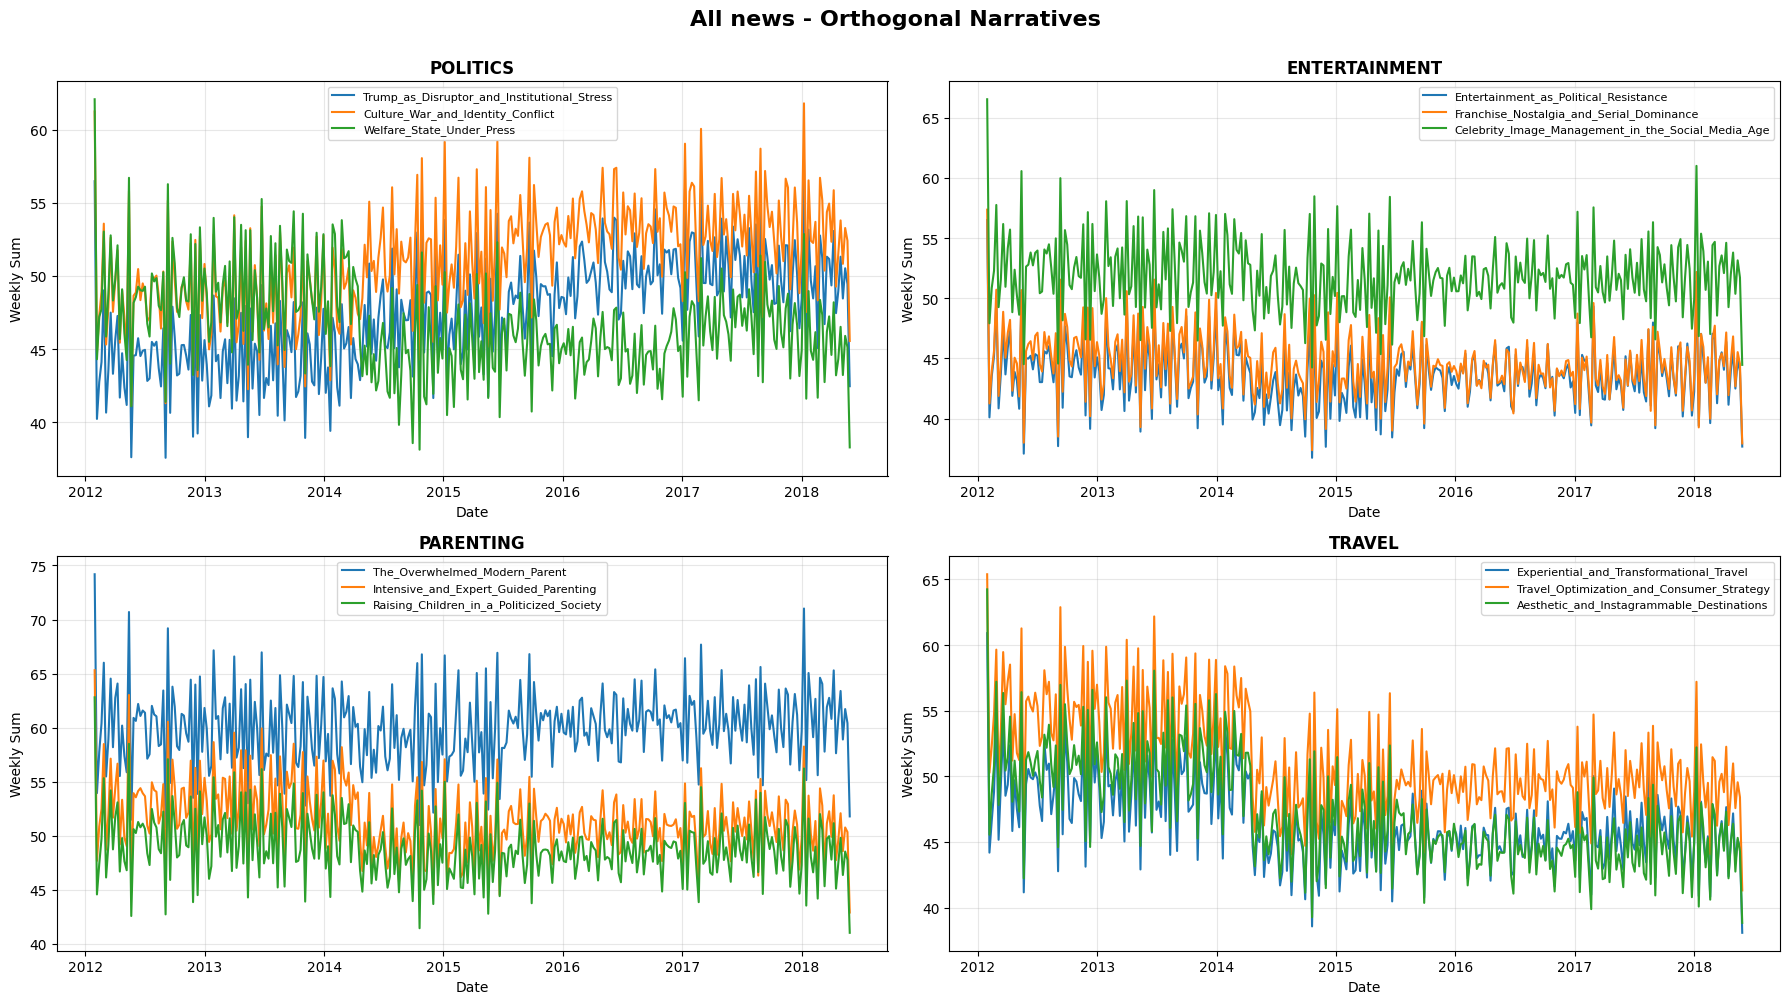

In [35]:
""" Visualization of cosine time series for pure narratives """


# Create subplots: one per chapter (6 chapters)
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()
    
for ax_idx, chapter in enumerate(chapter_names):
    chapter_orth_cols = [col for col in orthogonal_cols if col.startswith(chapter + ':')]
        
    if not chapter_orth_cols:
        axes[ax_idx].set_visible(False)
        continue
        
    for col in chapter_orth_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Sum', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
fig.suptitle('All news - Orthogonal Narratives', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


3) Residuals $R_i$

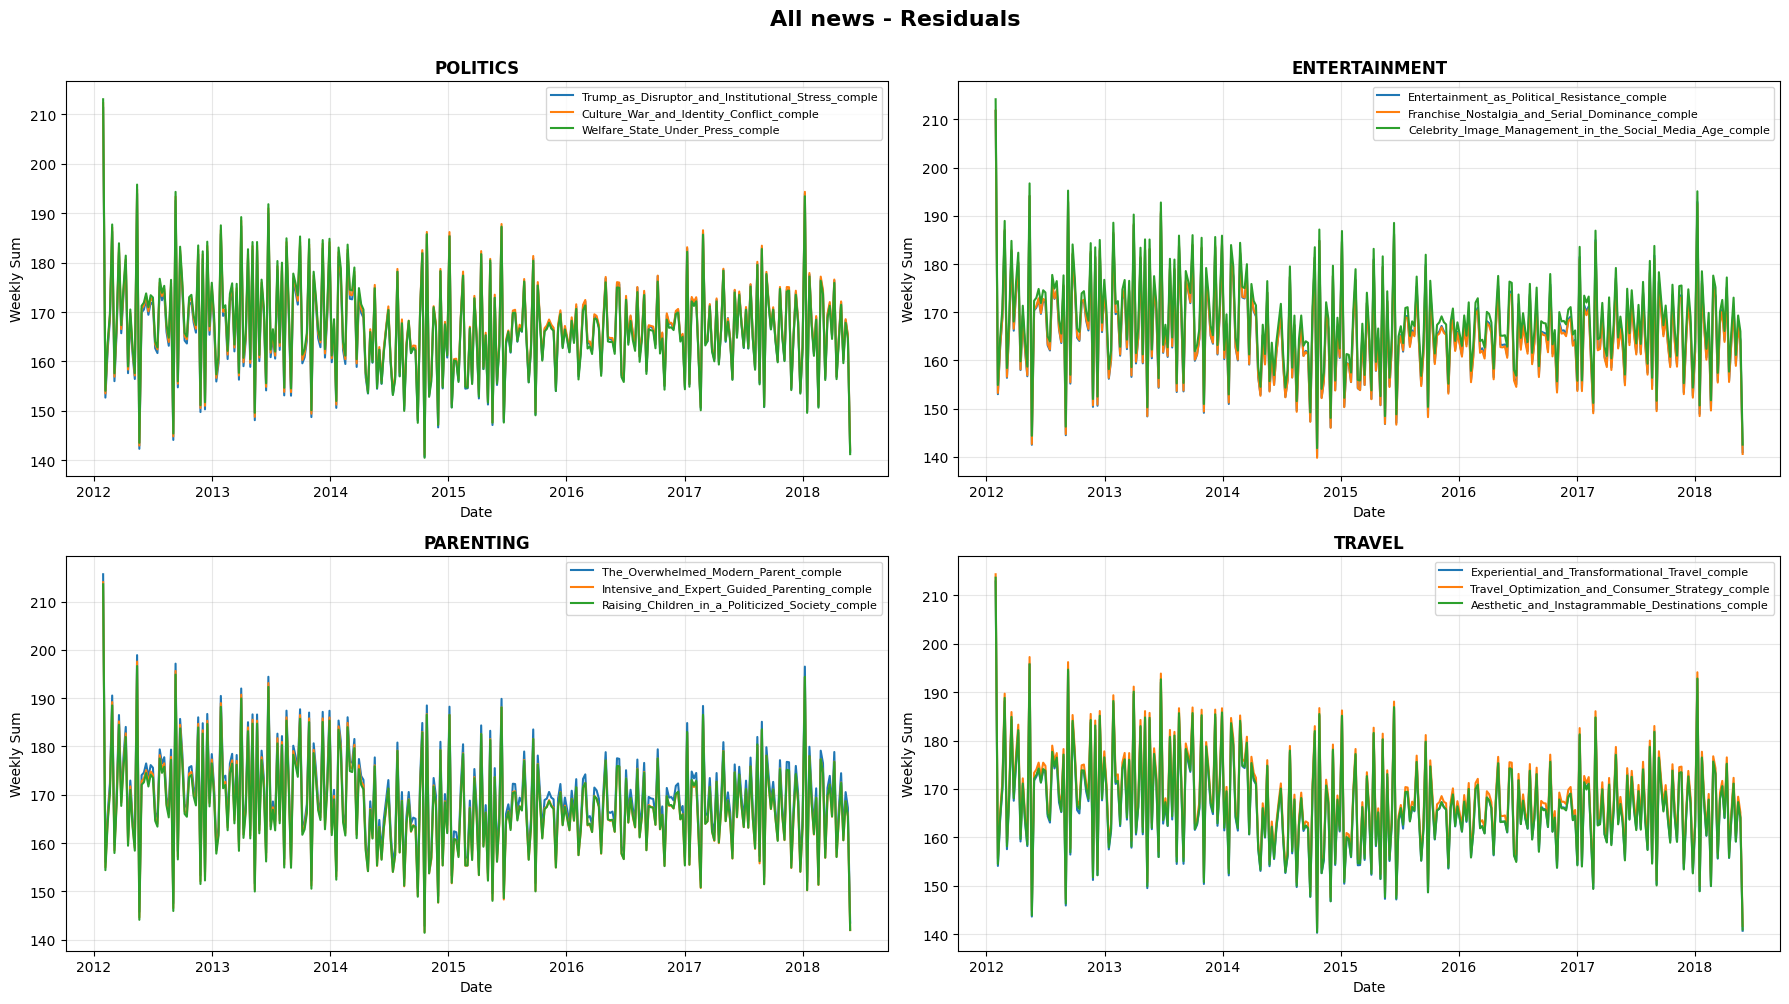

In [36]:
""" Visualization of cosine time series for pure narratives """


# Create subplots: one per chapter (6 chapters)
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()
    
for ax_idx, chapter in enumerate(chapter_names):
    chapter_residual_cols = [col for col in residuals_cols if col.startswith(chapter + ':')]
        
    if not chapter_residual_cols:
        axes[ax_idx].set_visible(False)
        continue
        
    for col in chapter_residual_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Sum', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
fig.suptitle('All news - Residuals', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


**V.2 Visualization excluding chapters from the dataset**

To monitor our results, we are excluding the news from the relevant chapter for the narratives

['ENTERTAINMENT', 'PARENTING', 'POLITICS', 'TRAVEL']


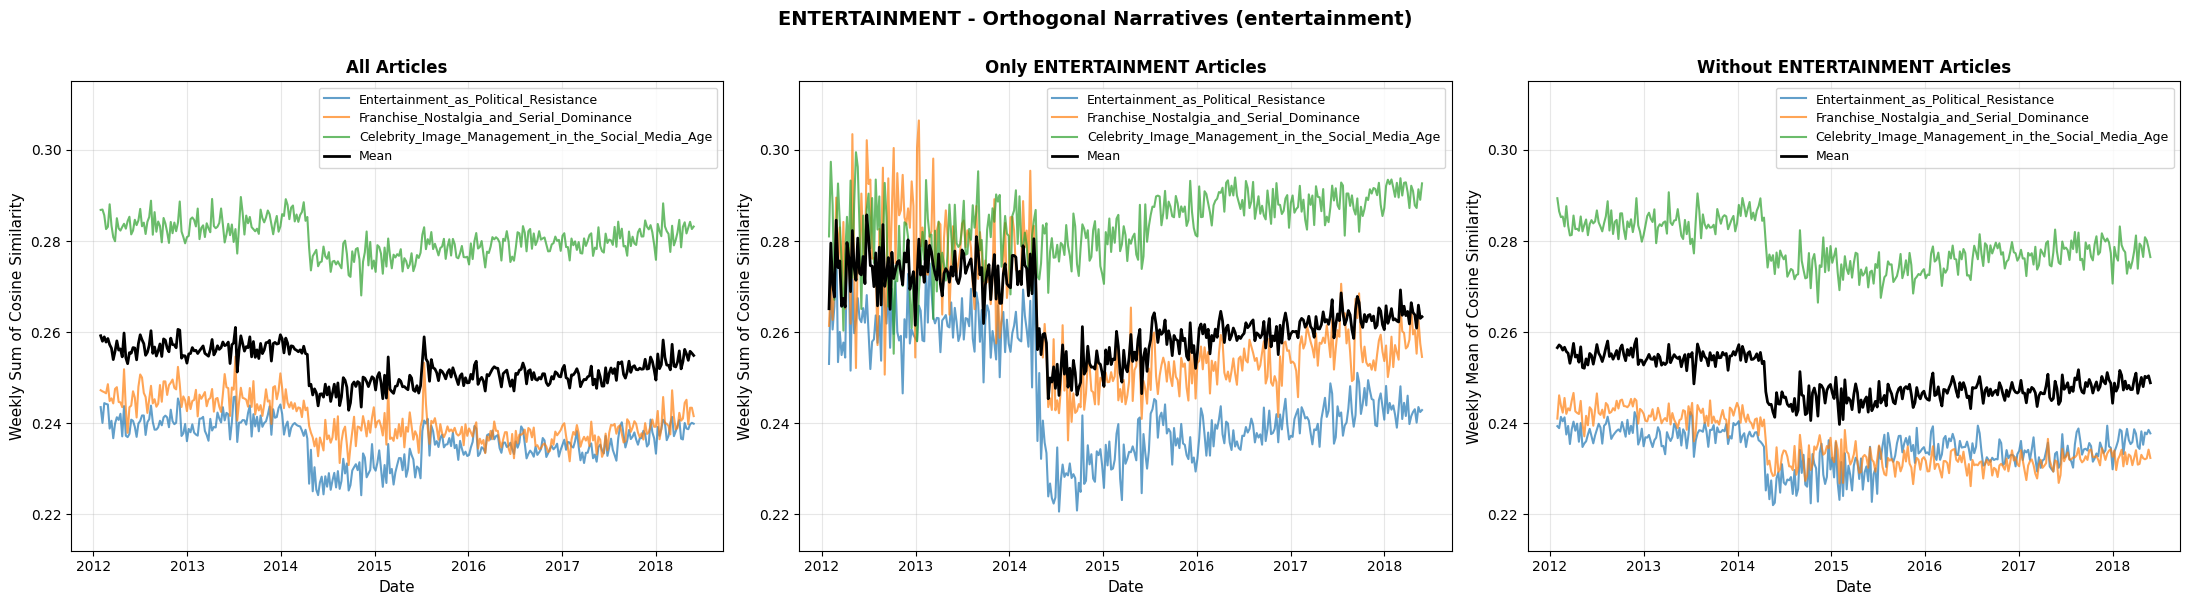

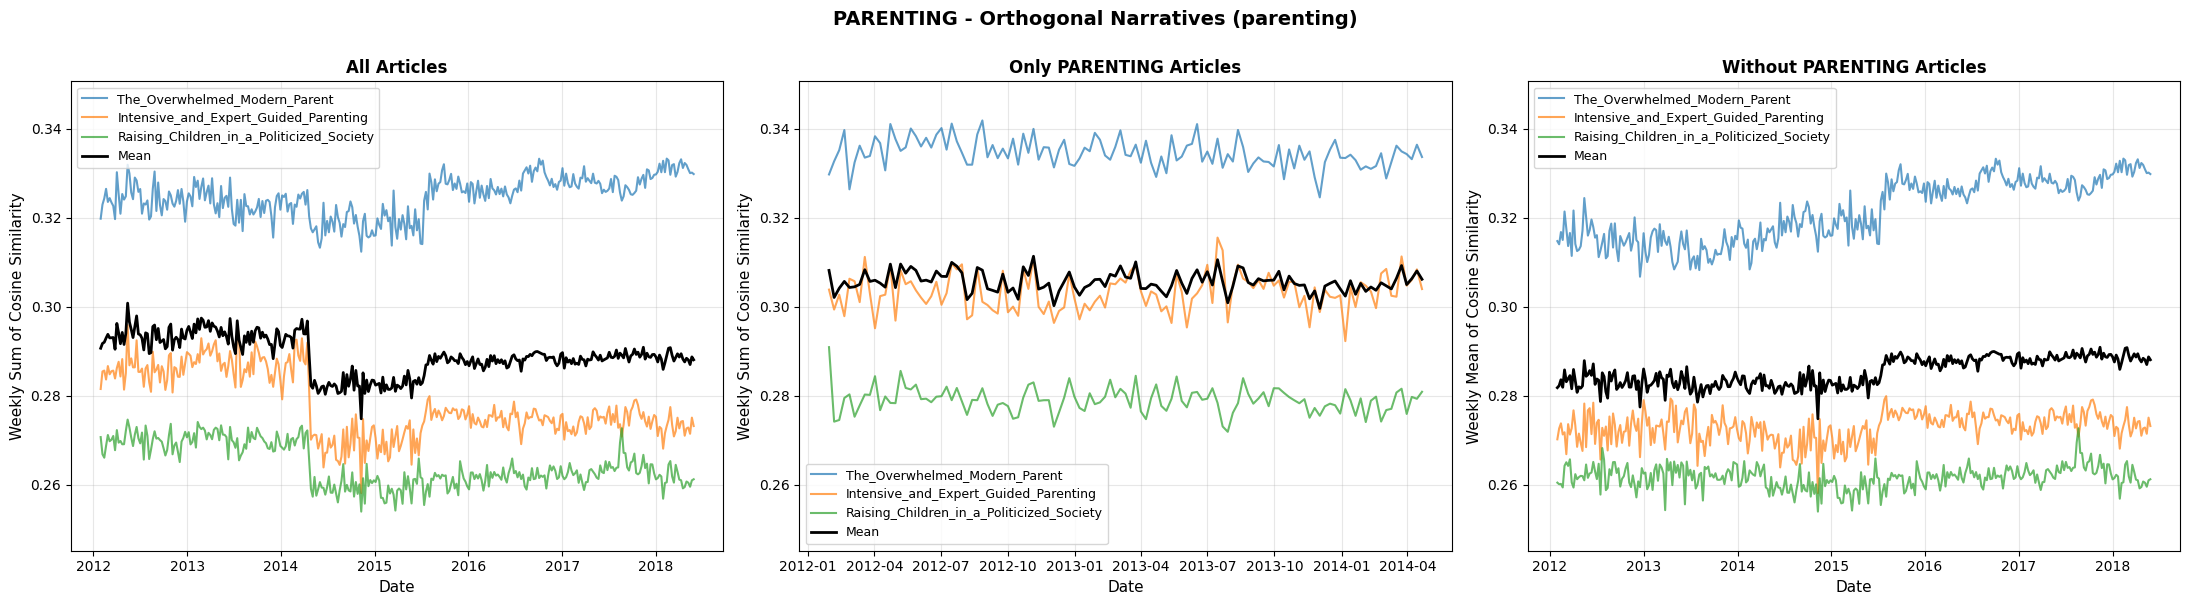

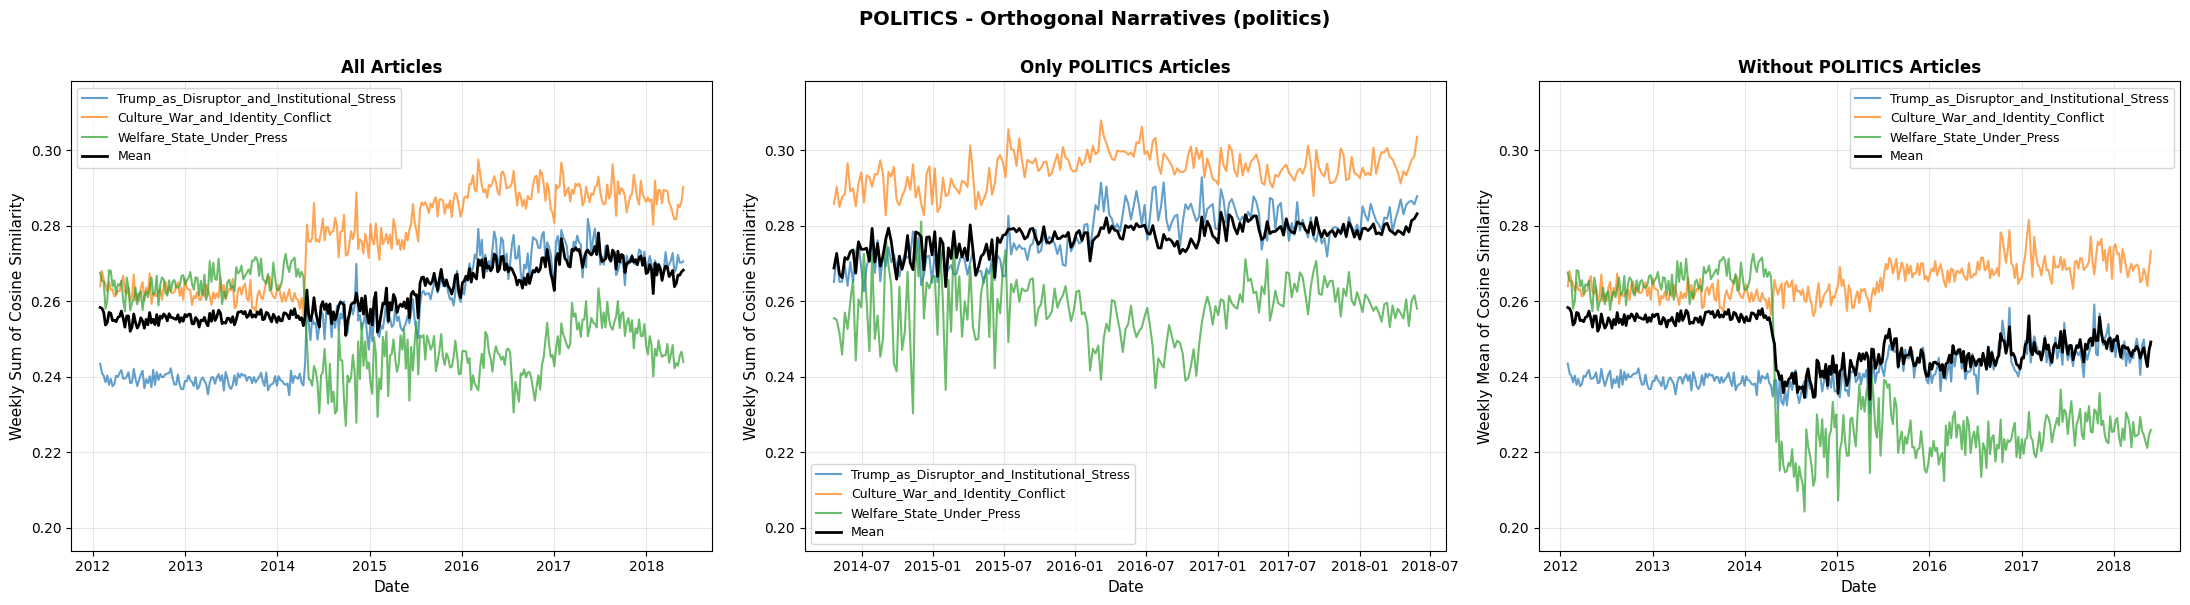

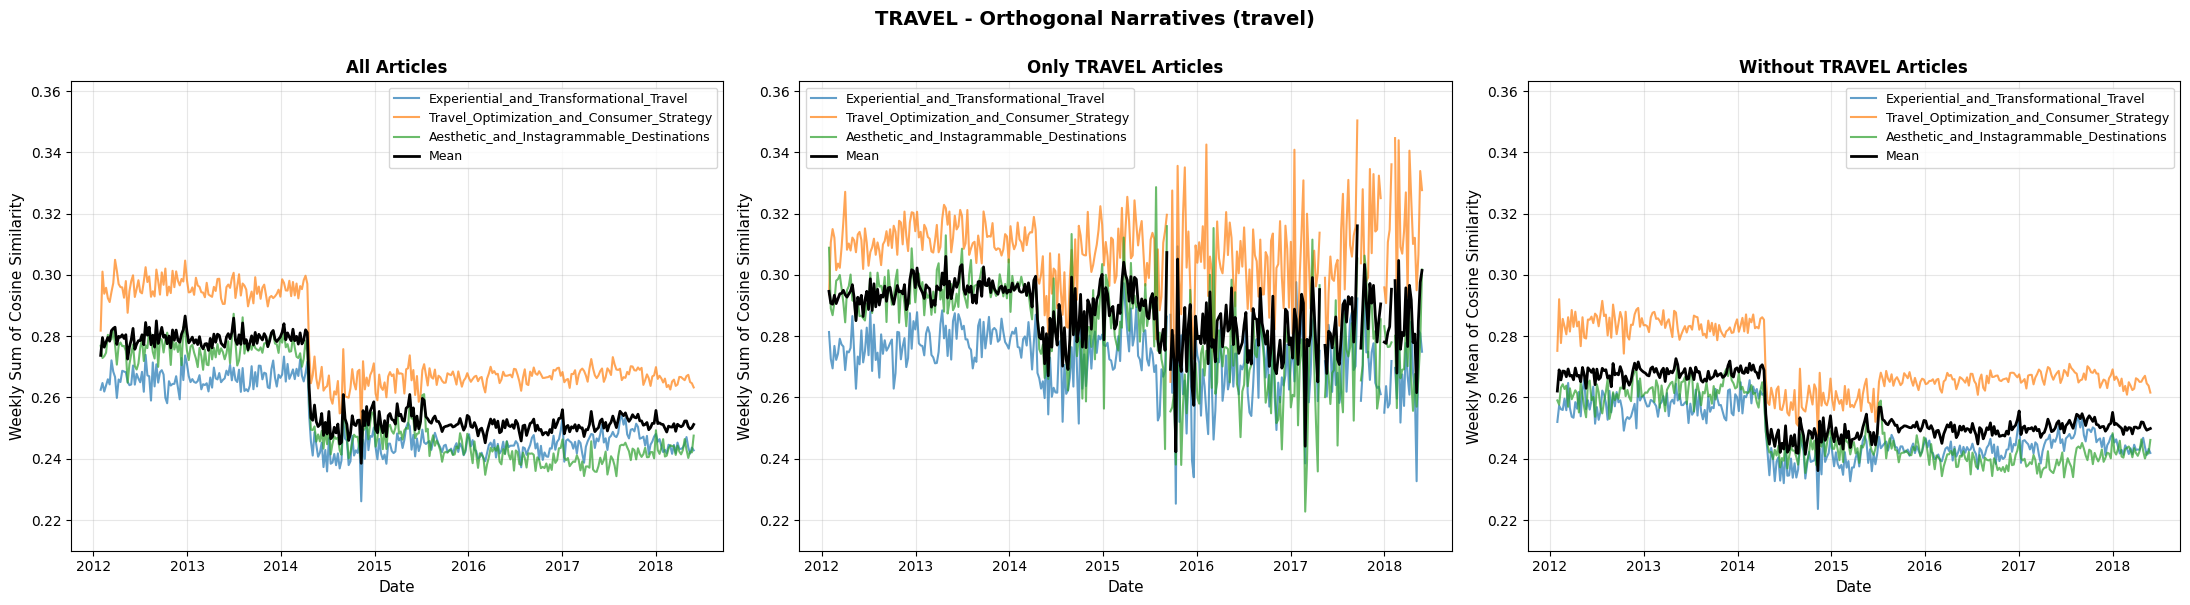

In [37]:
# Get unique news categories
news_categories = sorted(ts_df['category'].unique())
print(news_categories)

# Map news categories to their corresponding chapters
category_to_chapter = {
    'POLITICS': 'politics',
    'ENTERTAINMENT': 'entertainment',
    'TRAVEL': 'travel',
    'PARENTING': 'parenting'
}

""" Visualization of ORTHOGONAL narratives - 3 GRAPHS PER CATEGORY """

for news_cat in news_categories:
    if news_cat not in category_to_chapter:
        continue
    
    corresponding_chapter = category_to_chapter[news_cat]
    chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(corresponding_chapter + ':')]
    
    if not chapter_orthogonal_cols:
        continue
    
    # Filter data
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    ts_df_without_cat = ts_df[ts_df['category'] != news_cat]
    
    # Create 3-column figure
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))
    
    # Compute global min/max for consistent scaling
    y_min, y_max = float('inf'), float('-inf')
    
    for col in chapter_orthogonal_cols:
        # All data
        sim_all = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        y_min = min(y_min, sim_all.min())
        y_max = max(y_max, sim_all.max())
        
        # Only this category
        sim_cat = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        y_min = min(y_min, sim_cat.min())
        y_max = max(y_max, sim_cat.max())
        
        # Without this category
        sim_without = ts_df_without_cat.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        y_min = min(y_min, sim_without.min())
        y_max = max(y_max, sim_without.max())
    
    padding = (y_max - y_min) * 0.1
    y_min -= padding
    y_max += padding
    
    # GRAPH 1: All data
    all_curves_1 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax1.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_1.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_1:
        mean_curve_1 = np.mean(all_curves_1, axis=0)
        ax1.plot(dates, mean_curve_1, color='black', linewidth=2, label='Mean')
    
    ax1.set_title(f'All Articles', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Date', fontsize=11)
    ax1.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax1.set_ylim(y_min, y_max)
    ax1.legend(fontsize=9)
    ax1.grid(True, alpha=0.3)
    
    # GRAPH 2: Only this category
    all_curves_2 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax2.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_2.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_2:
        mean_curve_2 = np.mean(all_curves_2, axis=0)
        ax2.plot(dates, mean_curve_2, color='black', linewidth=2, label='Mean')
    
    ax2.set_title(f'Only {news_cat} Articles', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Date', fontsize=11)
    ax2.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax2.set_ylim(y_min, y_max)
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)
    
    # GRAPH 3: Without this category
    all_curves_3 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_without_cat.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax3.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_3.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_3:
        mean_curve_3 = np.mean(all_curves_3, axis=0)
        ax3.plot(dates, mean_curve_3, color='black', linewidth=2, label='Mean')
    
    ax3.set_title(f'Without {news_cat} Articles', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Date', fontsize=11)
    ax3.set_ylabel('Weekly Mean of Cosine Similarity', fontsize=11)
    ax3.set_ylim(y_min, y_max)
    ax3.legend(fontsize=9)
    ax3.grid(True, alpha=0.3)
    
    fig.suptitle(f'{news_cat.upper()} - Orthogonal Narratives ({corresponding_chapter})', fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

['ENTERTAINMENT', 'PARENTING', 'POLITICS', 'TRAVEL']


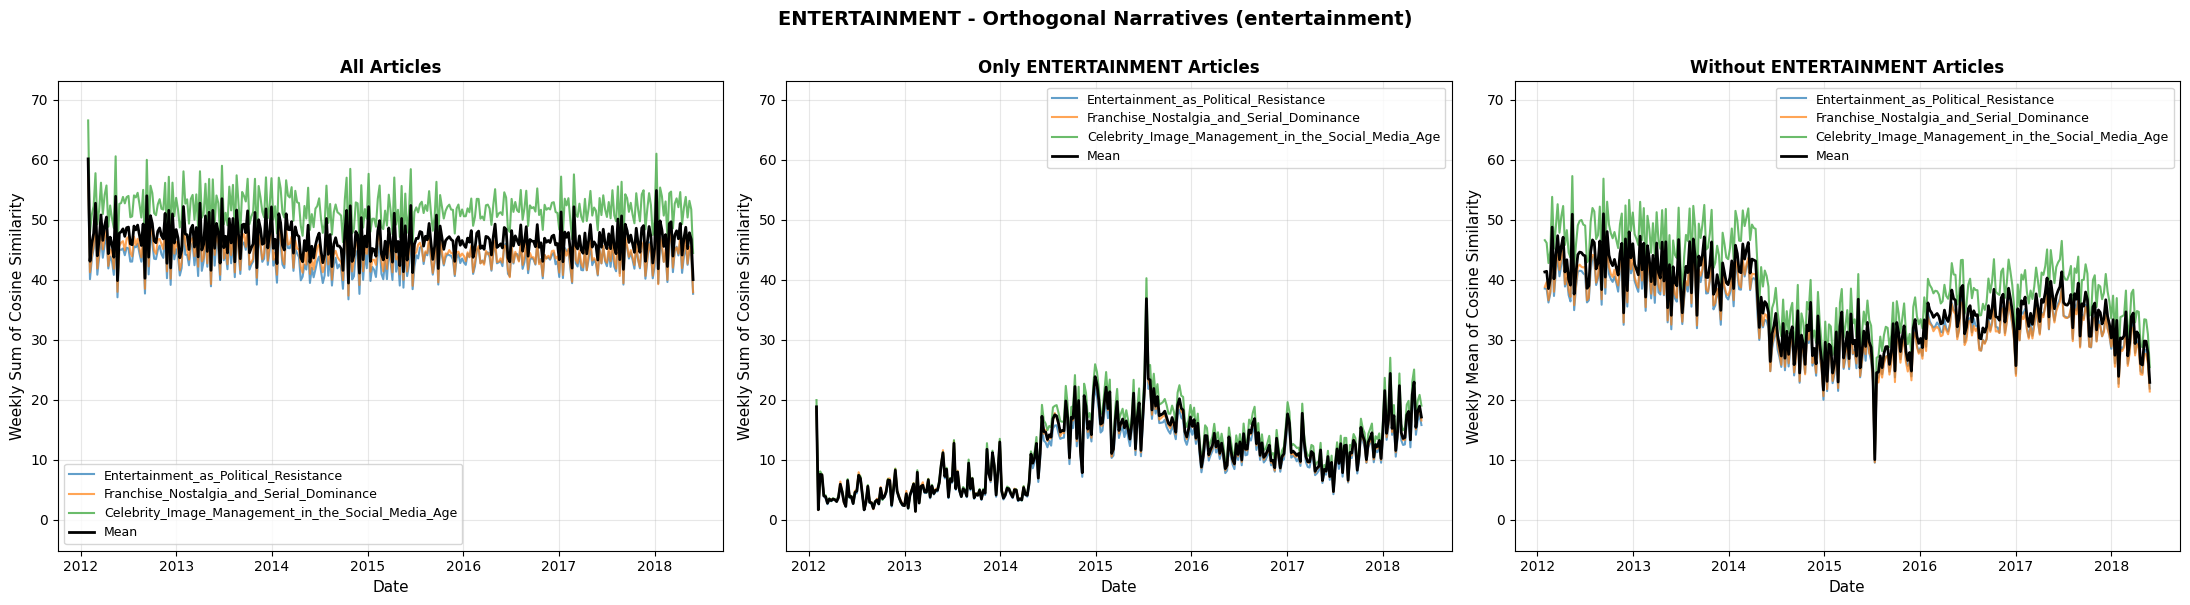

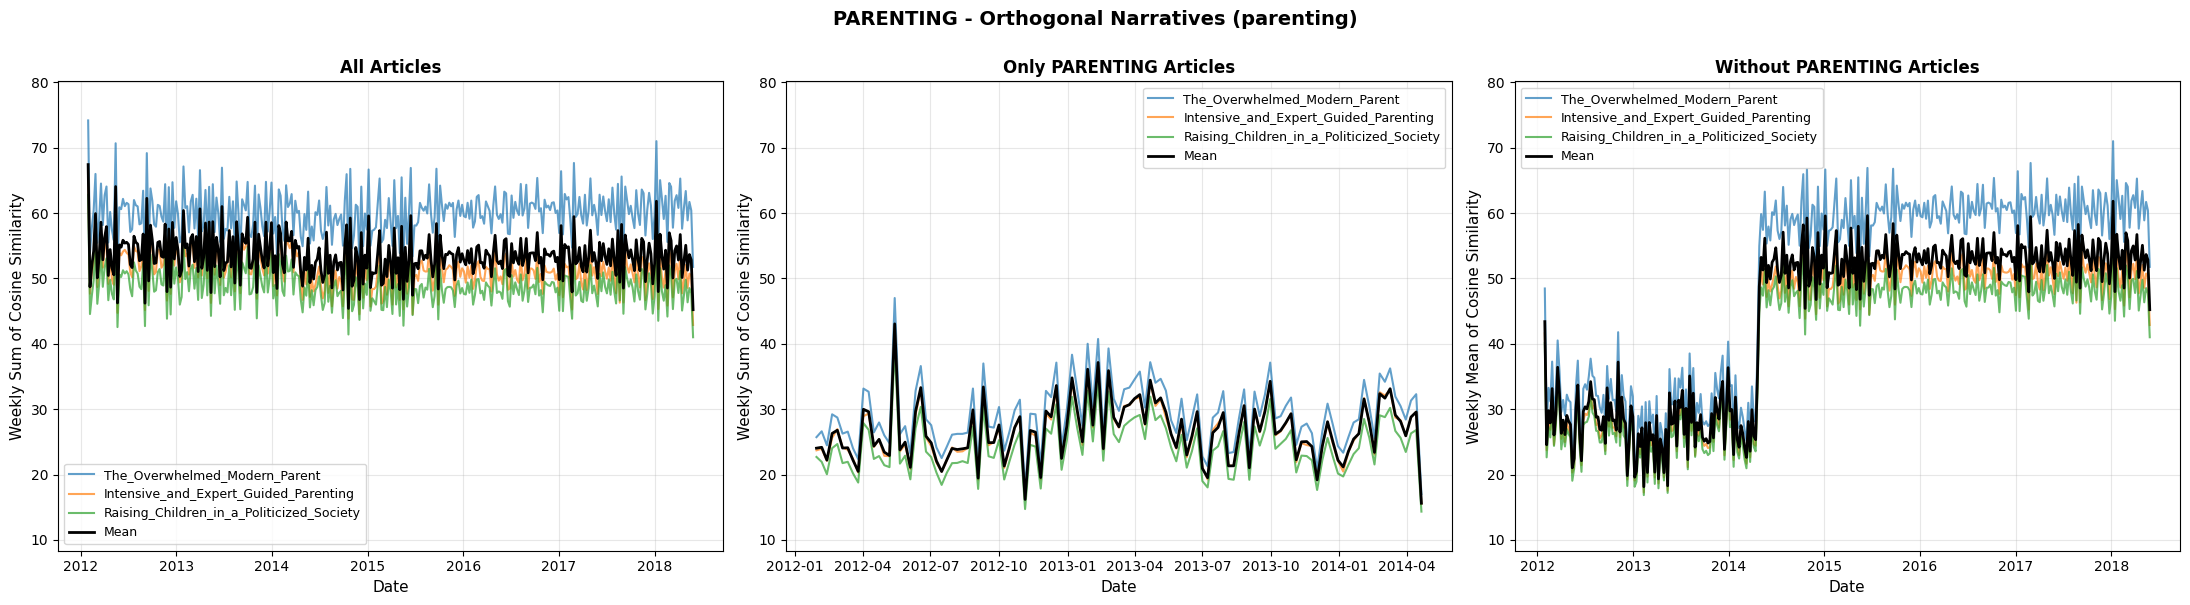

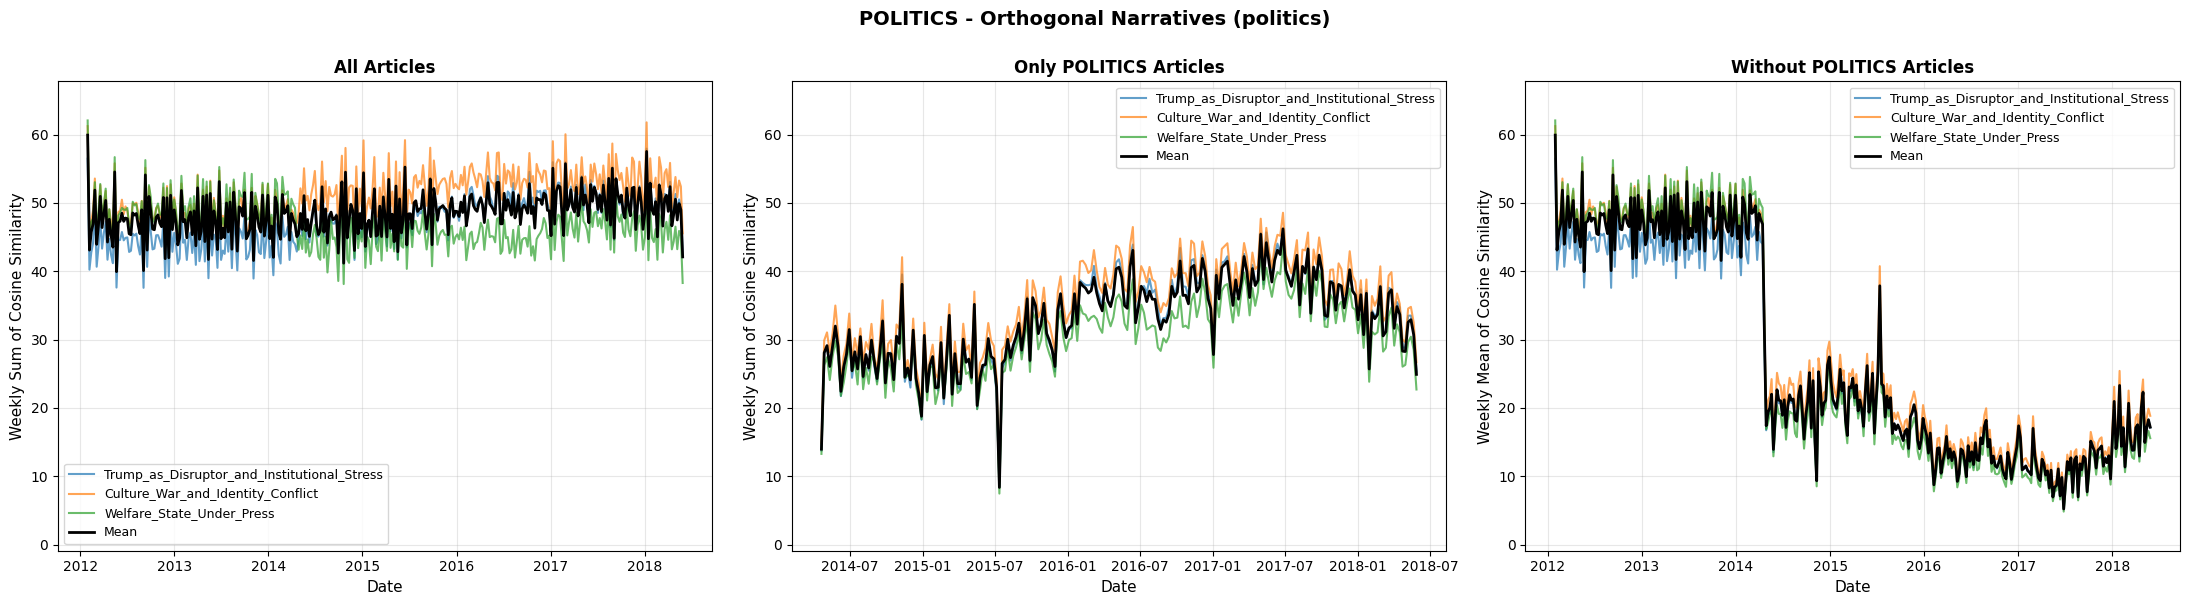

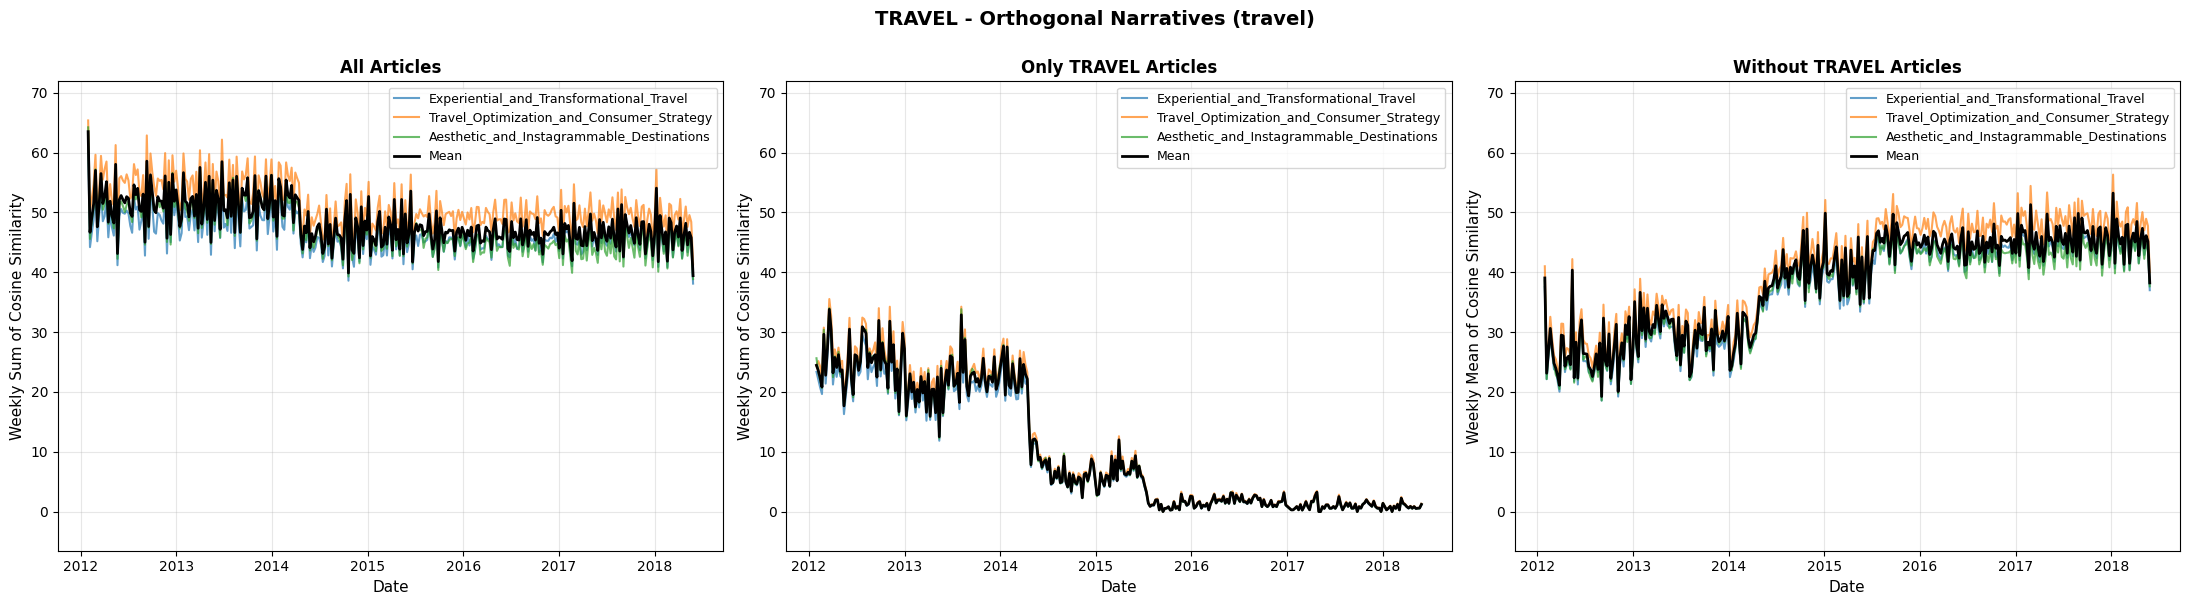

In [38]:
# Get unique news categories
news_categories = sorted(ts_df['category'].unique())
print(news_categories)

# Map news categories to their corresponding chapters
category_to_chapter = {
    'POLITICS': 'politics',
    'ENTERTAINMENT': 'entertainment',
    'TRAVEL': 'travel',
    'PARENTING': 'parenting'
}

""" Visualization of ORTHOGONAL narratives - 3 GRAPHS PER CATEGORY """

for news_cat in news_categories:
    if news_cat not in category_to_chapter:
        continue
    
    corresponding_chapter = category_to_chapter[news_cat]
    chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(corresponding_chapter + ':')]
    
    if not chapter_orthogonal_cols:
        continue
    
    # Filter data
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    ts_df_without_cat = ts_df[ts_df['category'] != news_cat]
    
    # Create 3-column figure
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))
    
    # Compute global min/max for consistent scaling
    y_min, y_max = float('inf'), float('-inf')
    
    for col in chapter_orthogonal_cols:
        # All data
        sim_all = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        y_min = min(y_min, sim_all.min())
        y_max = max(y_max, sim_all.max())
        
        # Only this category
        sim_cat = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        y_min = min(y_min, sim_cat.min())
        y_max = max(y_max, sim_cat.max())
        
        # Without this category
        sim_without = ts_df_without_cat.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        y_min = min(y_min, sim_without.min())
        y_max = max(y_max, sim_without.max())
    
    padding = (y_max - y_min) * 0.1
    y_min -= padding
    y_max += padding
    
    # GRAPH 1: All data
    all_curves_1 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax1.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_1.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_1:
        mean_curve_1 = np.mean(all_curves_1, axis=0)
        ax1.plot(dates, mean_curve_1, color='black', linewidth=2, label='Mean')
    
    ax1.set_title(f'All Articles', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Date', fontsize=11)
    ax1.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax1.set_ylim(y_min, y_max)
    ax1.legend(fontsize=9)
    ax1.grid(True, alpha=0.3)
    
    # GRAPH 2: Only this category
    all_curves_2 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax2.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_2.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_2:
        mean_curve_2 = np.mean(all_curves_2, axis=0)
        ax2.plot(dates, mean_curve_2, color='black', linewidth=2, label='Mean')
    
    ax2.set_title(f'Only {news_cat} Articles', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Date', fontsize=11)
    ax2.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax2.set_ylim(y_min, y_max)
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)
    
    # GRAPH 3: Without this category
    all_curves_3 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_without_cat.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax3.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_3.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_3:
        mean_curve_3 = np.mean(all_curves_3, axis=0)
        ax3.plot(dates, mean_curve_3, color='black', linewidth=2, label='Mean')
    
    ax3.set_title(f'Without {news_cat} Articles', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Date', fontsize=11)
    ax3.set_ylabel('Weekly Mean of Cosine Similarity', fontsize=11)
    ax3.set_ylim(y_min, y_max)
    ax3.legend(fontsize=9)
    ax3.grid(True, alpha=0.3)
    
    fig.suptitle(f'{news_cat.upper()} - Orthogonal Narratives ({corresponding_chapter})', fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()